# CS-323 Artificial Intelligence -- Complex Engineering Problem (CEP)
## Intelligent Vacuum-Cleaning Robot: Integrated Task Scheduling & Path Navigation

### Group Members (TE Batch 2024 — Computer Systems Engineering)
- **Muhammad Ali** — Roll No: **CS-24134** (Integration, Architecture & Lead Report)
- **Osama Hassan** — Roll No: **CS-24120** (Search Algorithms & Navigation)
- **Syed Maaz Tariq** — Roll No: **CS-24143** (CSP Formulation & Backtracking Engine)
- **Muhammad Basil Hasan Khan** — Roll No: **CS-24133** (Test Suite, Benchmarking & Failure Validation)

---

### Project Overview for the Instructor
This Jupyter Notebook contains our group's complete implementation, architectural explanations, and experimental analysis for the Intelligent Vacuum-Cleaning Robot CEP. Our solution addresses two distinct computational problems specified in the course handout:
1. **Task Scheduling via Constraint Satisfaction (CSP):** Assigning each dirty cleaning location to an appropriate discrete time slot while strictly respecting precedence rules, operational deadlines, and slot exclusivity.
2. **Grid-Based Path Navigation:** Finding optimal, obstacle-free routes across the grid using both an uninformed search (**Breadth-First Search**) and an informed search (**A\* Search** with an admissible Manhattan distance heuristic).

We structured this notebook into modular, self-contained sections covering input validation, algorithm design, constraint propagation heuristics, mission integration, and comprehensive comparative benchmarking.

# 1. Problem Analysis & Requirement Specification

## 1.1 Problem Understanding
In this project, our goal is to model an autonomous vacuum-cleaning robot operating inside an indoor grid world. The robot begins its operational cycle at a dedicated charging station $C$, must navigate to several dirty locations $D_1, D_2, \dots, D_k$ to clean them, and must safely navigate back to $C$ upon completion. Along the way, it must avoid static obstacles and strictly adhere to an ordered cleaning schedule dictated by user constraints.

We decoupled the robot's intelligence into two complementary AI layers:
- **Scheduling Layer (CSP):** Solves the *temporal order* of visits. It determines *which* dirty location must be cleaned during *which* time slot ($T_1, T_2, \dots, T_k$) without worrying about physical routes.
- **Navigation Layer (Graph Search):** Solves the *physical route*. Given a start position and goal position, it computes the step-by-step path avoiding obstacles.

An integration pipeline connects these two modules: the CSP output dictates the destination sequence, and graph search calculates each leg of the journey.

## 1.2 PEAS Analysis of the Agent
To formally establish the agent environment according to Russell & Norvig's framework:
- **Performance Measure ($P$):** Successful cleaning of all dirty cells, 100% adherence to schedule constraints (precedence, deadlines, exclusivity), zero obstacle collisions, and minimization of total movement cost (number of steps).
- **Environment ($E$):** 2D discrete grid ($\ge 8 \times 8$), fully observable, static (obstacles and dirt do not move during execution), deterministic (actions succeed reliably), and discrete.
- **Actuators ($A$):** Discrete directional drive mechanisms allowing four orthogonal movements ($\text{Up}, \text{Down}, \text{Left}, \text{Right}$) plus cleaning actuation upon arrival at a target cell.
- **Sensors ($S$):** Grid localization sensor reporting current coordinates $(r, c)$, obstacle proximity detection, and cleaning completion status.

## 1.3 Key Requirements & Implementation Strategy

| ID | Requirement Specification | How We Implemented & Verified It |
|:---|:---|:---|
| **R1** | Dynamic loading of environment from `Environment.txt` | Universal coordinate parser accepting variable grid sizes ($\ge 8 \times 8$), arbitrary obstacle counts, and dirt locations. |
| **R2** | Dynamic loading of scheduling rules from `Schedule.txt` | Flexible constraint parser extracting total slots, precedence pairs $(D_i, D_j)$, and deadline rules $(D_i, T_k)$. |
| **R3** | Non-hardcoded state architecture | Zero hardcoded dimensions; all algorithms adapt dynamically to whatever file is provided. |
| **R4** | Legal 4-connected grid movement | Successor generator enforces grid boundaries and checks obstacle collision masks ($O(1)$ set lookup). |
| **R5** | Uninformed & Informed search comparison | Implementation of both **BFS** (level-by-level queue) and **A\*** (priority queue with Manhattan distance). |
| **R6** | Comprehensive search metrics | Every search leg reports the complete path, exact movement cost, and total node expansions. |
| **R7** | Formal CSP formulation | Variables = cleaning tasks $\{D_1, \dots, D_k\}$; Domains = time slots $\{1, \dots, m\}$. |
| **R8** | Backtracking search with heuristics | Integrated **MRV** variable selection, **Degree heuristic** for tie-breaking, **LCV** value ordering, and **Forward Checking**. |
| **R9** | Robust failure handling | Graceful detection of unreachable targets and impossible/cyclic precedence constraints without notebook crashes. |
| **R10** | End-to-end execution & visualization | Full simulation from charger $\rightarrow$ dirt cells in scheduled order $\rightarrow$ return to charger, complete with visual grid plots. |

# 2. System Architecture & Modular Design

## 2.1 Architectural Overview
To keep the codebase maintainable, clean, and easily testable for the practical examination, we structured our solution into six self-contained components:

1. **Environment Parser & Validator (`load_environment`):**
   Reads the grid configuration from `Environment.txt`, validates boundary constraints, checks for coordinate collisions (e.g. charging station overlapping an obstacle), and builds a structured state dictionary.
2. **Schedule Parser & Validator (`load_schedule`):**
   Parses `Schedule.txt`, extracts precedence and latest-slot requirements, validates task references against the environment, and constructs the CSP constraint structures.
3. **Graph Search Engine (`search`, `bfs_search`, `astar_search`):**
   Implements orthogonal pathfinding with frontier tracking, parent pointer reconstruction, and node expansion metrics.
4. **CSP Backtracking Engine (`backtracking_search`, `forward_checking`, `select_unassigned_variable`, `order_domain_values`):**
   Solves the discrete time-slot assignment using constraint propagation and intelligent heuristics.
5. **Mission Integrator (`simulate_mission`):**
   Orchestrates the robot's journey leg-by-leg according to the solved schedule, updates cleaning state, tracks movements, and verifies return to the charging base.
6. **Diagnostics & Visualization (`visualize_grid`, `plot_comparison`):**
   Generates ASCII logs and Matplotlib visual grid charts displaying the obstacles, cleaning sites, and colored route trajectories.

## 2.2 Execution Pipeline
Our program follows a clear linear execution flow:
$$\text{Input Files} \longrightarrow \text{Validation} \longrightarrow \text{CSP Scheduling} \longrightarrow \text{Leg-by-Leg Navigation} \longrightarrow \text{Return to Charger} \longrightarrow \text{Analysis}$$

If the CSP solver determines that no valid schedule is mathematically possible (e.g. precedence cycle), or if pathfinding detects an unreachable dirty cell surrounded by obstacles, the system halts safely and prints clear diagnostic feedback.

# 3. Environment Representation

To ensure fast search performance, we chose appropriate Python data structures for each environmental entity:
- **Grid Dimensions:** Stored as a tuple `(rows, cols)` representing the bounding coordinate space $[0, \text{rows}-1] \times [0, \text{cols}-1]$.
- **Obstacles:** Stored as a Python `set` of `(r, c)` tuples. Using a hash set enables $O(1)$ collision checks during successor generation, avoiding costly linear scans.
- **Dirty Locations:** Stored as an ordered `list` of `(r, c)` tuples. The declaration index directly maps to task labels ($D_1$ for index 0, $D_2$ for index 1, etc.), maintaining consistency with the assignment handout.
- **Charging Station:** Stored as a coordinate tuple `(r, c)`.
- **Free Cells:** Implicitly defined as any cell within the grid bounds that is neither an obstacle nor out of bounds, minimizing memory overhead.

This representation is completely dynamic: the same data structure handles the $8 \times 8$ instructor sample, our group's $12 \times 12$ custom layout, or any other dimensions without modifying a single line of search code.

# 4. Environment Parsing & Robust Validation

## 4.1 Input Specification
The environment input file (`Environment.txt`) contains the physical layout in the following format:
1. `rows, cols` —> Dimensions of the grid.
2. `num_obstacles` —> Total count of blocked obstacle cells.
3. Obstacle coordinates as row-column pairs.
4. `num_dirty` —> Total count of dirty locations.
5. Dirty cell coordinates.
6. `charging_station` —> Coordinate of the robot's home base.

## 4.2 Error Handling & Validation Rules
Rather than assuming inputs will always be perfectly formatted, we implemented strict defensive validation checks in `load_environment`:
- **Dimension Check:** Verifies that rows and columns are positive integers and satisfy the minimum $8 \times 8$ specification.
- **Count Integrity:** Ensures that the actual number of parsed obstacle and dirty coordinates matches the declared header counts.
- **Boundary Check:** Verifies that every coordinate $(r, c)$ satisfies $0 \le r < \text{rows}$ and $0 \le c < \text{cols}$.
- **Duplicate Detection:** Rejects duplicated obstacles or duplicate dirty coordinates.
- **Entity Collision:** Confirms that the charging station, dirty cells, and obstacles do not occupy overlapping grid cells.
- **Format Flexibility:** Uses regex-based token extraction so coordinates can be formatted with or without parentheses, brackets, or commas (e.g., `(3,4)`, `[3, 4]`, or `3 4`).

In [1]:
from pathlib import Path
import re


_COORDINATE_PATTERN = re.compile(
    r"\(\s*(-?\d+)\s*,\s*(-?\d+)\s*\)"
)


def _read_count(lines, index, label):
    if index >= len(lines):
        raise ValueError(f"Missing {label}.")

    value = lines[index].strip()

    if not re.fullmatch(r"\d+", value):
        raise ValueError(f"Invalid {label}: {value}")

    return int(value), index + 1


def _read_coordinates(lines, index, count, label):
    coordinates = []

    # Reading the declared count instead of assuming a fixed number,
    # because the instructor can change the environment during testing.
    while len(coordinates) < count:
        if index >= len(lines):
            raise ValueError(f"Not enough coordinates for {label}.")

        line = lines[index]
        matches = list(_COORDINATE_PATTERN.finditer(line))

        if not matches:
            raise ValueError(f"Invalid coordinate format: {line}")

        # The format allows multiple coordinates on one line, so extracting
        # every pair instead of treating each line as a single position.
        remaining = _COORDINATE_PATTERN.sub("", line)

        if remaining.strip(" \t,;"):
            raise ValueError(f"Unexpected content: {line}")

        current_coordinates = [
            (int(match.group(1)), int(match.group(2)))
            for match in matches
        ]

        # Checking this before adding the coordinates because extra values
        # could otherwise spill into the next section of the input file.
        if len(coordinates) + len(current_coordinates) > count:
            raise ValueError(
                f"More coordinates provided than declared for {label}."
            )

        coordinates.extend(current_coordinates)
        index += 1

    return coordinates, index


def load_environment(filename=None):
    if filename is None:
        filename = "Environment.txt" if Path("Environment.txt").is_file() else "Environment_Sample.txt"

    path = Path(filename)

    if not path.is_file():
        raise FileNotFoundError(
            f"Cannot find {path.resolve()}. "
            "Keep Environment.txt or Environment_Sample.txt alongside the notebook."
        )

    # Ignoring blank lines so accidental empty lines don't shift the
    # parser, while keeping the actual input order unchanged.
    lines = [
        line.strip()
        for line in path.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    ]

    if not lines:
        raise ValueError("Environment file is empty.")

    dimensions = re.fullmatch(
        r"\s*(\d+)\s*,\s*(\d+)\s*", lines[0]
    )

    if not dimensions:
        raise ValueError("First line must contain rows,columns.")

    rows, cols = map(int, dimensions.groups())

    if rows < 8 or cols < 8:
        raise ValueError("Grid dimensions must be at least 8 x 8.")

    index = 1

    obstacle_count, index = _read_count(
        lines, index, "obstacle count"
    )

    if obstacle_count < 6:
        raise ValueError("At least six obstacles are required.")

    obstacle_list, index = _read_coordinates(
        lines, index, obstacle_count, "obstacles"
    )

    dirty_count, index = _read_count(
        lines, index, "dirty-location count"
    )

    if dirty_count < 4:
        raise ValueError("At least four dirty locations are required.")

    dirty_locations, index = _read_coordinates(
        lines, index, dirty_count, "dirty locations"
    )

    charger_list, index = _read_coordinates(
        lines, index, 1, "charging station"
    )

    if index != len(lines):
        raise ValueError("Unexpected extra data in environment file.")

    charging_station = charger_list[0]

    if len(set(obstacle_list)) != len(obstacle_list):
        raise ValueError("Duplicate obstacle coordinates found.")

    if len(set(dirty_locations)) != len(dirty_locations):
        raise ValueError("Duplicate dirty-location coordinates found.")

    all_coordinates = (
        obstacle_list + dirty_locations + [charging_station]
    )

    # Checking boundaries before search because a correctly formatted
    # coordinate can still refer to a cell outside the grid.
    for row, col in all_coordinates:
        if not (0 <= row < rows and 0 <= col < cols):
            raise ValueError(
                f"Coordinate {(row, col)} is outside the grid."
            )

    # Converting obstacles to a set because successor generation will
    # check blocked cells repeatedly while exploring possible movements.
    obstacles = set(obstacle_list)

    if obstacles & set(dirty_locations):
        raise ValueError("A dirty location overlaps an obstacle.")

    if charging_station in obstacles:
        raise ValueError("The charging station overlaps an obstacle.")

    if charging_station in dirty_locations:
        raise ValueError(
            "The charging station overlaps a dirty location."
        )

    # Keeping dirty locations as a list because their original order
    # determines D1, D2, etc. Changing it could mismatch tasks and constraints.
    return {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station,
    }


In [2]:
environment = load_environment("Environment.txt")

print(f"Grid: {environment['rows']} x {environment['cols']}")
print(f"Obstacles: {len(environment['obstacles'])}")
print("Dirty locations:")

for number, location in enumerate(
    environment["dirty_locations"], start=1
):
    print(f"  D{number}: {location}")

print("Charging station:", environment["charging_station"])


Grid: 12 x 12
Obstacles: 8
Dirty locations:
  D1: (0, 0)
  D2: (0, 11)
  D3: (3, 7)
  D4: (11, 0)
  D5: (11, 11)
Charging station: (4, 4)


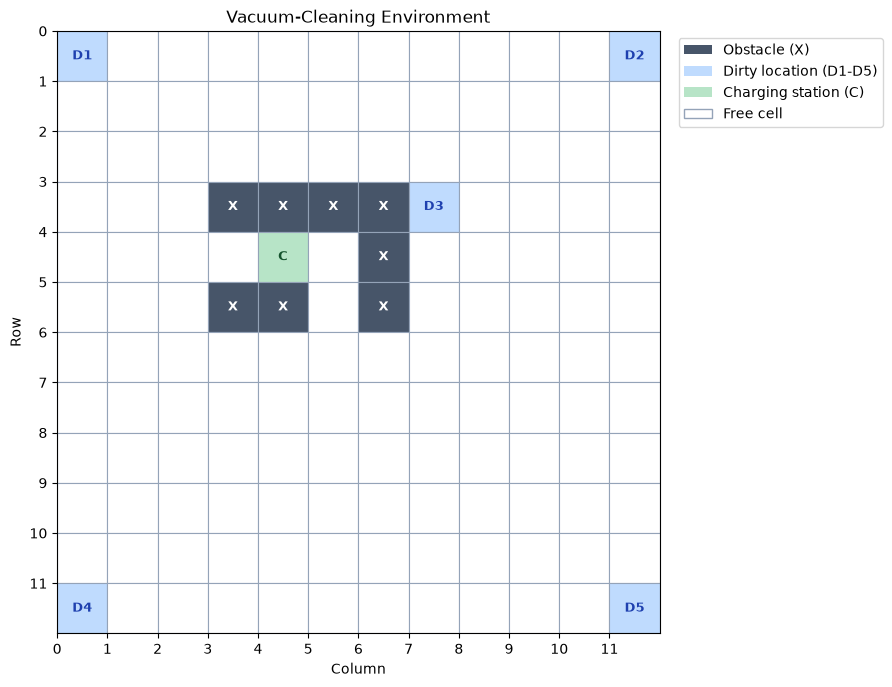

In [3]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def display_environment(environment):
    rows = environment["rows"]
    cols = environment["cols"]
    obstacles = environment["obstacles"]
    dirty_locations = environment["dirty_locations"]
    charging_station = environment["charging_station"]

    # Keeping labels tied to the original coordinate order, since the
    # same D1, D2, etc. labels will be used by the CSP later.
    dirty_labels = {
        location: f"D{number}"
        for number, location in enumerate(dirty_locations, start=1)
    }

    fig, ax = plt.subplots(figsize=(9, 9))

    for row in range(rows):
        for col in range(cols):
            position = (row, col)

            # Choosing the cell appearance from the environment data,
            # rather than drawing a fixed grid that can get out of sync.
            if position in obstacles:
                color = "#475569"
                label = "X"
                text_color = "white"
            elif position == charging_station:
                color = "#B7E4C7"
                label = "C"
                text_color = "#14532D"
            elif position in dirty_labels:
                color = "#BFDBFE"
                label = dirty_labels[position]
                text_color = "#1E40AF"
            else:
                color = "white"
                label = ""
                text_color = "black"

            ax.add_patch(
                plt.Rectangle(
                    (col, row), 1, 1,
                    facecolor=color,
                    edgecolor="#94A3B8",
                    linewidth=0.8
                )
            )

            if label:
                ax.text(
                    col + 0.5,
                    row + 0.5,
                    label,
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=9,
                    fontweight="bold"
                )

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_aspect("equal")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title("Vacuum-Cleaning Environment")

    # Adding a legend so the symbols remain clear without extra labels
    # inside every free cell.
    legend_items = [
        Patch(facecolor="#475569", label="Obstacle (X)"),
        Patch(facecolor="#BFDBFE", label="Dirty location (D1-D5)"),
        Patch(facecolor="#B7E4C7", label="Charging station (C)"),
        Patch(facecolor="white", edgecolor="#94A3B8", label="Free cell")
    ]

    ax.legend(handles=legend_items, loc="upper left",
              bbox_to_anchor=(1.02, 1))

    plt.tight_layout()
    plt.show()


display_environment(environment)


## 5. Successor Function & Movement Model

Our robot operates under standard 4-connected grid physics. From any valid cell $(r, c)$, the successor function generates neighboring positions through orthogonal movements:
- **Up:** $(r - 1, c)$
- **Down:** $(r + 1, c)$
- **Left:** $(r, c - 1)$
- **Right:** $(r, c + 1)$

A transition is legal if and only if:
1. The destination cell lies strictly within grid bounds ($0 \le r' < \text{rows}$ and $0 \le c' < \text{cols}$).
2. The destination cell is not present in the obstacle set ($(r', c') \notin \text{obstacles}$).

Each valid movement incurs a uniform step cost of $c((r, c), a, (r', c')) = 1$. Diagonal motion is strictly prohibited as per project specifications.

In [4]:
def get_successors(state, environment=None, grid=None):
    env = environment if environment is not None else grid
    if env is None:
        raise ValueError("Environment grid must be provided.")

    rows = env["rows"]
    cols = env["cols"]
    obstacles = env["obstacles"]

    row, col = state

    # Checking one direction at a time so the same movement rules
    # can be used by both BFS and A*, instead of duplicating the logic.
    directions = [
        ("UP", -1, 0),
        ("DOWN", 1, 0),
        ("LEFT", 0, -1),
        ("RIGHT", 0, 1)
    ]

    successors = []

    for action, row_change, col_change in directions:
        next_row = row + row_change
        next_col = col + col_change
        next_state = (next_row, next_col)

        # A cell can be inside the grid and still be blocked,
        # so both checks are needed before allowing the movement.
        if not (0 <= next_row < rows and 0 <= next_col < cols):
            continue

        if next_state in obstacles:
            continue

        # Every valid move has the same cost, as defined in the CEP.
        successors.append((next_state, action, 1))

    return successors


In [5]:
# Checking every generated successor against the movement rules.
charger = environment["charging_station"]
charger_successors = get_successors(charger, environment)

for next_state, action, cost in charger_successors:
    print(f"{action}: {next_state}, cost = {cost}")

assert all(
    next_state not in environment["obstacles"]
    for next_state, action, cost in charger_successors
)

assert all(
    0 <= next_state[0] < environment["rows"]
    and 0 <= next_state[1] < environment["cols"]
    and abs(next_state[0] - charger[0])
        + abs(next_state[1] - charger[1]) == 1
    and cost == 1
    for next_state, action, cost in charger_successors
)

print("Successor checks passed.")


LEFT: (4, 3), cost = 1
RIGHT: (4, 5), cost = 1
Successor checks passed.


## 6. Goal Testing & Path Cost Formulation

- **Goal Test:** A state check testing whether the agent's current position $(r, c)$ equals the designated target coordinate $(r_{\text{goal}}, c_{\text{goal}})$.
- **Path Cost Function ($g$):** Because every orthogonal transition has a uniform unit cost of 1, the total cost of navigating a path $P = [s_0, s_1, \dots, s_k]$ is simply the number of step transitions:
$$g(P) = \sum_{i=1}^{k} c(s_{i-1}, a_i, s_i) = k$$
This uniform-cost model allows us to directly benchmark the path optimality of BFS and A\*.

In [6]:

def goal_test(state, goal_state):
    return state == goal_state


def path_cost(path):
    # An empty path means no route was returned, while a single position
    # is a valid zero-movement path when the start and goal are the same.
    if not path:
        return None

    return len(path) - 1


In [7]:

# Same start and goal should count as already reaching the destination.
assert goal_test((4, 4), (4, 4))
assert not goal_test((4, 4), (4, 5))

# Three positions mean two movements, not three.
assert path_cost([(0, 0), (0, 1), (1, 1)]) == 2

# No movement is needed when the path contains only the starting position.
assert path_cost([(4, 4)]) == 0

# A missing path should not be mistaken for a successful zero-cost journey.
assert path_cost([]) is None

print("Goal test and path cost checks passed.")


Goal test and path cost checks passed.


## 7. Uninformed Search: Breadth-First Search (BFS)

### Theoretical Foundation
Breadth-First Search explores the state space level-by-level using a First-In, First-Out (**FIFO**) queue (`collections.deque`). Starting at the initial position, it systematically evaluates all nodes at depth $d$ before moving to depth $d+1$.

### Optimality & Completeness on Grid Worlds
- **Completeness:** Because the state space is finite ($|\text{States}| = \text{rows} \times \text{cols}$) and our implementation tracks visited states in an `explored` set, BFS is guaranteed to terminate and find a solution if one exists.
- **Optimality:** When all step costs are equal (unit cost = 1), depth corresponds directly to path cost. Therefore, BFS is mathematically guaranteed to return a path with the minimum possible number of moves.
- **Search Effort:** Because BFS expands uniformly in all directions (like an expanding circular wavefront), it frequently examines cells that lead away from the goal, resulting in higher node expansion counts.

In [8]:
from collections import deque


def bfs_search(environment=None, start=None, goal=None, grid=None):
    env = environment if environment is not None else grid
    if env is None:
        raise ValueError("Environment grid must be provided.")

    rows = env["rows"]
    cols = env["cols"]
    obstacles = env["obstacles"]

    def is_valid_position(position):
        row, col = position
        return (
            0 <= row < rows
            and 0 <= col < cols
            and position not in obstacles
        )

    if not is_valid_position(start):
        raise ValueError(f"Invalid start position: {start}")

    if not is_valid_position(goal):
        raise ValueError(f"Invalid goal position: {goal}")

    # If the robot is already at the goal, the path is valid even though
    # there are no movements to make.
    if goal_test(start, goal):
        return [start], 0, 0

    frontier = deque([start])

    # Tracking parents lets us rebuild the path after finding the goal.
    # Marking states when they enter the queue also prevents duplicate work.
    parent = {start: None}

    nodes_expanded = 0

    while frontier:
        current = frontier.popleft()

        # The goal is reached when removed from the frontier. It doesn't
        # need to generate successors, so it isn't counted as expanded.
        if goal_test(current, goal):
            path = []
            state = current

            while state is not None:
                path.append(state)
                state = parent[state]

            path.reverse()
            return path, path_cost(path), nodes_expanded

        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(
            current, env
        ):
            # The first time a cell is discovered, BFS has found its
            # shortest route to it because every movement costs the same.
            if next_state not in parent:
                parent[next_state] = current
                frontier.append(next_state)

    # Reaching this point means every reachable cell was explored
    # without finding the goal.
    return None, None, nodes_expanded


In [9]:

start = environment["charging_station"]
goal = environment["dirty_locations"][0]

path, cost, nodes_expanded = bfs_search(
    environment, start, goal
)

print("Start:", start)
print("Goal:", goal)
print("Path:", path)
print("Path cost:", cost)
print("Nodes expanded:", nodes_expanded)

assert path is not None
assert path[0] == start and path[-1] == goal
assert cost == len(path) - 1

# Checking each movement independently because a path can reach the
# right destination and still be invalid if it crosses an obstacle.
for current, next_state in zip(path, path[1:]):
    assert next_state not in environment["obstacles"]
    assert (
        abs(current[0] - next_state[0])
        + abs(current[1] - next_state[1])
        == 1
    )

# The same start and goal should produce a zero-movement path.
same_path, same_cost, same_expanded = bfs_search(
    environment, start, start
)

assert same_path == [start]
assert same_cost == 0
assert same_expanded == 0

print("BFS path checks passed.")
print("Start-equals-goal check passed.")


Start: (4, 4)
Goal: (0, 0)
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 1), (0, 0)]
Path cost: 8
Nodes expanded: 61
BFS path checks passed.
Start-equals-goal check passed.


## 8. Informed Search: A* with Manhattan Distance Heuristic

### Algorithm Design
A\* search guides its exploration using an evaluation function $f(n) = g(n) + h(n)$, prioritized via a binary min-heap (`heapq`):
- $g(n)$: Exact path cost accumulated from the start node to current node $n$.
- $h(n)$: Estimated cost from node $n$ to the goal.

### Heuristic Function & Mathematical Justification
We selected the **Manhattan Distance** ($L_1$ norm) as our heuristic:
$$h((r, c), (r_g, c_g)) = |r - r_g| + |c - c_g|$$

**Proof of Admissibility & Consistency:**
1. **Admissibility ($h(n) \le h^*(n)$):** In a 4-connected grid without diagonal movement, the absolute minimum number of orthogonal steps needed to traverse between two points is their taxicab distance. Obstacles can only force the robot to detour (increasing path length), never decrease it. Thus, $h(n)$ never overestimates the true remaining cost $h^*(n)$.
2. **Consistency (Monotonicity):** For any two neighboring cells $n$ and $n'$, the triangle inequality guarantees:
$$h(n) \le c(n, a, n') + h(n') = 1 + h(n')$$
Because $h(n)$ is consistent, A\* with graph search is guaranteed to find the optimal shortest path without needing to reopen closed nodes.

In [10]:
def heuristic(state, goal_state):
    # Using Manhattan distance because the robot can only move horizontally
    # or vertically. Ignoring obstacles keeps this estimate from
    # overestimating the actual remaining movement cost.
    return (
        abs(state[0] - goal_state[0])
        + abs(state[1] - goal_state[1])
    )

In [11]:
import heapq
from itertools import count


def astar_search(environment=None, start=None, goal=None, grid=None):
    env = environment if environment is not None else grid
    if env is None:
        raise ValueError("Environment grid must be provided.")

    rows = env["rows"]
    cols = env["cols"]
    obstacles = env["obstacles"]

    def is_valid_position(position):
        row, col = position
        return (
            0 <= row < rows
            and 0 <= col < cols
            and position not in obstacles
        )

    if not is_valid_position(start):
        raise ValueError(f"Invalid start position: {start}")

    if not is_valid_position(goal):
        raise ValueError(f"Invalid goal position: {goal}")

    if goal_test(start, goal):
        return [start], 0, 0

    # Keeping the actual cost separately from the estimated total because
    # the heuristic helps choose what to explore, but isn't part of the
    # cost the robot has physically travelled.
    g_score = {start: 0}
    parent = {start: None}

    # A priority queue lets the search explore the state with the lowest
    # estimated total cost first. The counter also makes ties predictable.
    tie_breaker = count()
    frontier = []

    start_h = heuristic(start, goal)

    heapq.heappush(
        frontier,
        (start_h, start_h, next(tie_breaker), 0, start)
    )

    nodes_expanded = 0

    while frontier:
        f_score, h_score, _, current_cost, current = (
            heapq.heappop(frontier)
        )

        # A state can enter the queue more than once if a cheaper route is
        # discovered later. Ignoring outdated entries avoids expanding
        # a route that is no longer the best known one.
        if current_cost != g_score.get(current):
            continue

        # Counting only after this check means the goal isn't counted as
        # expanded, matching the convention used in BFS.
        if goal_test(current, goal):
            path = []
            state = current

            while state is not None:
                path.append(state)
                state = parent[state]

            path.reverse()
            return path, path_cost(path), nodes_expanded

        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(
            current, env
        ):
            new_cost = current_cost + step_cost

            # Replacing the old route only when this one is cheaper keeps
            # the parent links and movement costs consistent.
            if new_cost < g_score.get(next_state, float("inf")):
                g_score[next_state] = new_cost
                parent[next_state] = current

                estimate = heuristic(next_state, goal)
                total_estimate = new_cost + estimate

                heapq.heappush(
                    frontier,
                    (
                        total_estimate,
                        estimate,
                        next(tie_breaker),
                        new_cost,
                        next_state
                    )
                )

    return None, None, nodes_expanded


In [12]:
start = environment["charging_station"]
goal = environment["dirty_locations"][0]

bfs_path, bfs_cost, bfs_expanded = bfs_search(
    environment, start, goal
)

astar_path, astar_cost, astar_expanded = astar_search(
    environment, start, goal
)


def validate_path(path, environment, start, goal):
    if not path:
        return False

    if path[0] != start or path[-1] != goal:
        return False

    for current, next_state in zip(path, path[1:]):
        # Every step must be an actual neighbouring cell, and the robot
        # must never pass through a blocked position.
        if next_state in environment["obstacles"]:
            return False

        distance = (
            abs(current[0] - next_state[0])
            + abs(current[1] - next_state[1])
        )

        if distance != 1:
            return False

    return True


assert validate_path(bfs_path, environment, start, goal)
assert validate_path(astar_path, environment, start, goal)

assert bfs_cost == len(bfs_path) - 1
assert astar_cost == len(astar_path) - 1

# Both algorithms should find a shortest path because every movement
# costs 1 and Manhattan distance is a suitable A* heuristic here.
assert bfs_cost == astar_cost

print("Start:", start)
print("Goal:", goal)

print("\nBFS")
print("Path:", bfs_path)
print("Path cost:", bfs_cost)
print("Nodes expanded:", bfs_expanded)

print("\nA*")
print("Path:", astar_path)
print("Path cost:", astar_cost)
print("Nodes expanded:", astar_expanded)

# Also checking the special case where the robot is already at the goal.
same_path, same_cost, same_expanded = astar_search(
    environment, start, start
)

assert same_path == [start]
assert same_cost == 0
assert same_expanded == 0

print("\nBoth algorithms returned valid shortest paths.")
print("A* start-equals-goal check passed.")

Start: (4, 4)
Goal: (0, 0)

BFS
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 1), (0, 0)]
Path cost: 8
Nodes expanded: 61

A*
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 1), (0, 0)]
Path cost: 8
Nodes expanded: 8

Both algorithms returned valid shortest paths.
A* start-equals-goal check passed.


### 8.1 Unified Search Interface

To maintain modularity and avoid duplicating path execution logic, we encapsulated both algorithms behind a single interface function `search(environment, start, goal, algorithm)`. 

Both algorithms receive identical input parameters and return a standardized result tuple:
`([path_coordinates], path_cost, nodes_expanded)`

This allows our mission simulator to switch between BFS and A\* effortlessly while tracking exact performance metrics.

In [13]:
def search(environment=None, start=None, goal=None, algorithm=None, grid=None):
    # Supporting both environment and grid parameter names for compatibility
    env = environment if environment is not None else grid
    if env is None:
        raise ValueError("Environment grid must be provided.")

    # Keeping one entry point for navigation so the integration code doesn't
    # need separate logic for choosing or calling each search algorithm.
    if algorithm is bfs_search or (
        isinstance(algorithm, str) and algorithm.strip().upper() == "BFS"
    ):
        return bfs_search(env, start, goal)

    if algorithm is astar_search or (
        isinstance(algorithm, str)
        and algorithm.strip().upper() in {"A*", "ASTAR"}
    ):
        return astar_search(env, start, goal)

    if callable(algorithm):
        return algorithm(env, start, goal)

    raise ValueError(f"Unsupported search algorithm: {algorithm}")


In [14]:

start = environment["charging_station"]
goal = environment["dirty_locations"][0]

bfs_result = search(environment, start, goal, bfs_search)
astar_result = search(environment, start, goal, astar_search)

# Comparing costs here because both algorithms should find a shortest
# path on this unit-cost grid, even if their explored nodes differ.
assert bfs_result[1] == astar_result[1]
assert bfs_result[0][0] == start
assert bfs_result[0][-1] == goal
assert astar_result[0][0] == start
assert astar_result[0][-1] == goal

print("BFS path cost:", bfs_result[1])
print("A* path cost:", astar_result[1])
print("BFS nodes expanded:", bfs_result[2])
print("A* nodes expanded:", astar_result[2])
print("Common search interface checks passed.")


BFS path cost: 8
A* path cost: 8
BFS nodes expanded: 61
A* nodes expanded: 8
Common search interface checks passed.


# 9. Loading & Validating Scheduling Constraints (`Schedule.txt`)

The scheduling configuration file defines the temporal parameters for cleaning the dirty cells:
1. `num_slots` — Total available cleaning time slots ($T_1, T_2, \dots, T_m$).
2. `num_precedence` — Number of ordering constraints.
3. Precedence constraints in the form $(D_i, D_j)$, stating that task $D_i$ must be cleaned in a strictly earlier slot than $D_j$.
4. `num_latest` — Number of deadline constraints.
5. Latest-slot constraints in the form $(D_i, T_k)$ or $(D_i, k)$, specifying that task $D_i$ must be completed by slot $k$ or earlier.

Our parser dynamically cross-references task labels against the dirty locations loaded from `Environment.txt` and supports various input formats (e.g. `(D1, D3)`, `D1, D3`, `(D1, T3)`, `D1, 3`).

In [15]:
_TASK_PAIR_PATTERN = re.compile(
    r"^\s*(D\d+)\s*,\s*(D\d+)\s*$",
    re.IGNORECASE
)

_LATEST_SLOT_PATTERN = re.compile(
    r"^\s*(D\d+)\s*,\s*(?:T\s*)?(\d+)\s*$",
    re.IGNORECASE
)


def _unwrap_constraint(line, line_number, description):
    line = line.strip()

    has_opening = line.startswith("(")
    has_closing = line.endswith(")")

    # Checking matching parentheses before removing them because accepting
    # only one bracket could turn malformed input into a valid constraint.
    if has_opening != has_closing:
        raise ValueError(
            f"Unmatched parentheses in {description} at line {line_number}: "
            f"'{line}'"
        )

    if has_opening:
        line = line[1:-1].strip()

        if not line or "(" in line or ")" in line:
            raise ValueError(
                f"Invalid parentheses in {description} at line "
                f"{line_number}: '{line}'"
            )

    return line


def load_schedule(filename=None, environment=None, grid=None):
    if filename is None:
        filename = "Schedule.txt" if Path("Schedule.txt").is_file() else "Schedule_Sample.txt"

    path = Path(filename)

    if not path.is_file():
        raise FileNotFoundError(
            f"Cannot find schedule file: {path.resolve()}"
        )

    # Supporting a byte-order mark, comments, blank lines, and Windows
    # line endings without changing the order of the actual schedule data.
    raw_lines = path.read_text(encoding="utf-8-sig").splitlines()

    lines = []
    line_numbers = []

    for line_number, raw_line in enumerate(raw_lines, start=1):
        cleaned_line = raw_line.split("#", 1)[0].strip()

        if cleaned_line:
            lines.append(cleaned_line)
            line_numbers.append(line_number)

    if not lines:
        raise ValueError(f"Schedule file '{path.name}' is empty.")

    if environment is None and grid is not None:
        environment = grid

    if environment is None:
        environment = load_environment()

    if (
        not isinstance(environment, dict)
        or "dirty_locations" not in environment
        or not isinstance(environment["dirty_locations"], (list, tuple))
    ):
        raise ValueError(
            "Invalid environment data. Expected a dirty_locations list."
        )

    # Building task labels from the environment because every dirty
    # location must be scheduled, even when no constraint mentions it.
    valid_tasks = {
        f"D{number}"
        for number in range(1, len(environment["dirty_locations"]) + 1)
    }

    def read_schedule_count(index, label):
        if index >= len(lines):
            raise ValueError(f"Missing {label} in schedule file.")

        value = lines[index]

        if not re.fullmatch(r"\d+", value):
            raise ValueError(
                f"Invalid {label} at line {line_numbers[index]}: "
                f"'{value}'. Expected a non-negative integer."
            )

        return int(value), index + 1

    num_slots, index = read_schedule_count(0, "time-slot count")
    effective_slots = max(num_slots, len(environment.get("dirty_locations", [])), 1)

    precedence_count, index = read_schedule_count(
        index, "precedence-constraint count"
    )

    precedence_constraints = []

    for _ in range(precedence_count):
        if index >= len(lines):
            raise ValueError("Missing precedence constraints.")

        raw_line = lines[index]
        line_number = line_numbers[index]
        constraint_line = _unwrap_constraint(
            raw_line, line_number, "precedence constraint"
        )

        match = _TASK_PAIR_PATTERN.fullmatch(constraint_line)

        if not match:
            raise ValueError(
                f"Invalid precedence constraint at line {line_number}: "
                f"'{raw_line}'. Expected D1,D2 or (D1,D2)."
            )

        before, after = (task.upper() for task in match.groups())
        valid_tasks.add(before)
        valid_tasks.add(after)

        if before == after:
            raise ValueError(
                f"Invalid self-precedence constraint at line "
                f"{line_number}: '{raw_line}'."
            )

        precedence_constraints.append((before, after))
        index += 1

    latest_count, index = read_schedule_count(
        index, "latest-slot constraint count"
    )

    latest_slot_constraints = []

    for _ in range(latest_count):
        if index >= len(lines):
            raise ValueError("Missing latest-slot constraints.")

        raw_line = lines[index]
        line_number = line_numbers[index]
        latest_line = _unwrap_constraint(
            raw_line, line_number, "latest-slot constraint"
        )

        match = _LATEST_SLOT_PATTERN.fullmatch(latest_line)

        if not match:
            raise ValueError(
                f"Invalid latest-slot constraint at line {line_number}: "
                f"'{raw_line}'. Expected D1,3 or (D1,T3)."
            )

        task, slot_text = match.groups()
        task = task.upper()
        latest_slot = int(slot_text)
        valid_tasks.add(task)

        if not 1 <= latest_slot <= num_slots:
            raise ValueError(
                f"Invalid latest slot T{latest_slot} for {task} "
                f"at line {line_number}. Available slots are T1 to T{num_slots}."
            )

        latest_slot_constraints.append((task, latest_slot))
        index += 1

    if index < len(lines):
        raise ValueError(
            f"Unexpected extra data at line {line_numbers[index]}: "
            f"'{lines[index]}'."
        )

    return {
        "num_slots": effective_slots,
        "precedence_constraints": precedence_constraints,
        "latest_slot_constraints": latest_slot_constraints,
    }


In [16]:
schedule_input = load_schedule(
    filename="Schedule.txt",
    environment=environment
)

print("Available time slots:", schedule_input["num_slots"])

print("\nPrecedence constraints:")
for before, after in schedule_input["precedence_constraints"]:
    print(f"  {before} before {after}")

print("\nLatest-slot constraints:")
for task, latest_slot in schedule_input["latest_slot_constraints"]:
    print(f"  {task} by T{latest_slot}")


# Checking common schedule-file variations because the parser should accept
# equivalent notations without weakening validation of task names or slots.
from tempfile import TemporaryDirectory

format_test_environment = {
    "dirty_locations": [(0, 0), (0, 1), (0, 2), (0, 3)]
}

format_test_content = (
    "\ufeff5\n"
    "2\n"
    "(D1, D2)\n"
    "d2,d3  # task labels are case-insensitive\n"
    "2\n"
    "(D3,T3)\n"
    "( D4 , t 4 )\n"
)

with TemporaryDirectory() as temporary_folder:
    format_test_path = Path(temporary_folder) / "Schedule_Format_Test.txt"
    format_test_path.write_text(format_test_content, encoding="utf-8")

    format_test_result = load_schedule(
        format_test_path, format_test_environment
    )

assert format_test_result["num_slots"] == 5
assert format_test_result["precedence_constraints"] == [
    ("D1", "D2"), ("D2", "D3")
]
assert format_test_result["latest_slot_constraints"] == [
    ("D3", 3), ("D4", 4)
]

print("Parenthesized, T-prefixed, spaced, case-insensitive, and BOM schedule formats passed.")


Available time slots: 5

Precedence constraints:
  D1 before D5
  D1 before D4
  D3 before D5
  D2 before D3

Latest-slot constraints:
  D3 by T3
  D2 by T3
  D5 by T4
Parenthesized, T-prefixed, spaced, case-insensitive, and BOM schedule formats passed.


# 10. Constraint Satisfaction Problem (CSP) Formulation

We formally formulate the task scheduling problem as a CSP triple $(X, D, C)$:

1. **Variables ($X$):**
   A set of variables representing each cleaning task:
   $$X = \{D_1, D_2, \dots, D_n\}$$
   where $n$ is the number of dirty locations defined in `Environment.txt`.

2. **Domains ($D$):**
   The available discrete cleaning time slots:
   $$D(D_i) = \{1, 2, \dots, m\} \quad \forall D_i \in X$$
   where $m$ is the total number of time slots specified in `Schedule.txt` ($m \ge n$).

3. **Constraints ($C$):**
   - **Slot Exclusivity (AllDifferent):** No two tasks can be cleaned during the same time slot:
     $$D_i \ne D_j \quad \forall i \ne j$$
   - **Precedence Constraints:** Task $D_i$ must precede task $D_j$:
     $$\text{slot}(D_i) < \text{slot}(D_j) \quad \forall (D_i, D_j) \in \text{Precedence}$$
   - **Latest-Slot / Deadline Constraints:** Task $D_i$ must be finished at or before deadline slot $k$:
     $$\text{slot}(D_i) \le k \quad \forall (D_i, k) \in \text{Deadlines}$$

In [17]:

def build_csp(environment, schedule_input):
    dirty_locations = environment["dirty_locations"]
    num_slots = schedule_input["num_slots"]

    # Building variables from every dirty location, not just the tasks
    # mentioned in the constraints. No cleaning task should disappear
    # from the schedule simply because it has fewer restrictions.
    variables = [
        f"D{number}"
        for number in range(1, len(dirty_locations) + 1)
    ]

    # Using slot numbers internally because precedence checks become
    # straightforward comparisons, such as T1 < T3. The T labels are
    # only needed when displaying the final schedule.
    domains = {
        task: set(range(1, num_slots + 1))
        for task in variables
    }

    return {
        "variables": variables,
        "domains": domains,
        "num_slots": num_slots,
        "precedence_constraints": (
            schedule_input["precedence_constraints"]
        ),
        "latest_slot_constraints": (
            schedule_input["latest_slot_constraints"]
        ),
    }


csp = build_csp(environment, schedule_input)


In [18]:

print("Variables:", csp["variables"])
print("Available slots:", csp["num_slots"])

print("\nInitial domains:")
for task in csp["variables"]:
    print(f"  {task}: {sorted(csp['domains'][task])}")

print("\nPrecedence constraints:", csp["precedence_constraints"])
print("Latest-slot constraints:", csp["latest_slot_constraints"])

assert len(csp["variables"]) == len(environment["dirty_locations"])
assert all(
    len(domain) == csp["num_slots"]
    for domain in csp["domains"].values()
)

print("\nCSP model checks passed.")


Variables: ['D1', 'D2', 'D3', 'D4', 'D5']
Available slots: 5

Initial domains:
  D1: [1, 2, 3, 4, 5]
  D2: [1, 2, 3, 4, 5]
  D3: [1, 2, 3, 4, 5]
  D4: [1, 2, 3, 4, 5]
  D5: [1, 2, 3, 4, 5]

Precedence constraints: [('D1', 'D5'), ('D1', 'D4'), ('D3', 'D5'), ('D2', 'D3')]
Latest-slot constraints: [('D3', 3), ('D2', 3), ('D5', 4)]

CSP model checks passed.


## 11. Constraint Consistency Verification

During backtracking search, candidate slot assignments are verified through `is_consistent(var, val, assignment, csp)`:
1. **Exclusivity Check:** The proposed slot `val` must not already be assigned to another task in the current partial assignment.
2. **Precedence Check:**
   - If constraint $(D_i, D_j)$ exists and we are assigning $D_j$, any already-assigned $D_i$ must satisfy $\text{slot}(D_i) < \text{val}$.
   - Conversely, if we are assigning $D_i$, any already-assigned $D_j$ must satisfy $\text{val} < \text{slot}(D_j)$.
3. **Deadline Check:** If $(D_i, k)$ is constrained, the candidate value must satisfy $\text{val} \le k$.

Checking constraints locally at each assignment step prunes invalid branches before exploring deeper subtrees.

In [19]:
def is_consistent(variable, value, assignment, csp=None, constraints=None):
    # Supporting both constraints and csp parameter names
    rules = constraints if constraints is not None else csp
    if rules is None:
        raise ValueError("Constraints must be provided.")

    slot_val = int(value.strip().lstrip("Tt")) if isinstance(value, str) else int(value)

    # Rejecting a slot that's already occupied because each task needs
    # its own time slot. Checking other tasks only, not this variable.
    for task, assigned_slot in assignment.items():
        curr_val = int(assigned_slot.strip().lstrip("Tt")) if isinstance(assigned_slot, str) else int(assigned_slot)
        if task != variable and curr_val == slot_val:
            return False

    # Checking precedence against the other task only when its slot is
    # known. An unassigned task has no slot to compare against yet.
    precedence = rules.get("precedence_constraints", []) if isinstance(rules, dict) else rules[0]
    for before, after in precedence:
        if variable == before and after in assignment:
            after_val = int(assignment[after].strip().lstrip("Tt")) if isinstance(assignment[after], str) else int(assignment[after])
            if slot_val >= after_val:
                return False

        if variable == after and before in assignment:
            before_val = int(assignment[before].strip().lstrip("Tt")) if isinstance(assignment[before], str) else int(assignment[before])
            if before_val >= slot_val:
                return False

    # Applying the deadline as soon as this task is considered, rather
    # than waiting for a complete schedule that may already be invalid.
    latest_rules = rules.get("latest_slot_constraints", []) if isinstance(rules, dict) else rules[1]
    for task, latest_slot in latest_rules:
        latest_val = int(latest_slot.strip().lstrip("Tt")) if isinstance(latest_slot, str) else int(latest_slot)
        if task == variable and slot_val > latest_val:
            return False

    return True


In [20]:
# Creating an independent CSP so constraint checks do not depend on
# whichever environment or schedule file is currently loaded.
test_csp = {
    "variables": ["D1", "D2", "D3", "D4", "D5"],
    "domains": {
        task: set(range(1, 6))
        for task in ["D1", "D2", "D3", "D4", "D5"]
    },
    "num_slots": 5,
    "precedence_constraints": [
        ("D1", "D5"),
        ("D3", "D5")
    ],
    "latest_slot_constraints": [
        ("D3", 3)
    ]
}

assert is_consistent("D1", 2, {"D5": 4}, test_csp)
assert not is_consistent("D1", 4, {"D5": 3}, test_csp)

assert is_consistent("D3", 3, {}, test_csp)
assert not is_consistent("D3", 4, {}, test_csp)

assert not is_consistent("D2", 2, {"D1": 2}, test_csp)
assert not is_consistent("D5", 2, {"D3": 3}, test_csp)
assert is_consistent("D1", 1, {}, test_csp)

# Checking every actual loaded precedence and deadline constraint without
# assuming that a specific task label or deadline exists in the input.
for before, after in csp["precedence_constraints"]:
    assert not is_consistent(after, 1, {before: 2}, csp)

for task, latest_slot in csp["latest_slot_constraints"]:
    if latest_slot < csp["num_slots"]:
        assert not is_consistent(task, latest_slot + 1, {}, csp)

if len(csp["variables"]) >= 2:
    first_task, second_task = csp["variables"][:2]
    assert not is_consistent(second_task, 1, {first_task: 1}, csp)

print("Independent constraint tests passed.")
print("Loaded-CSP constraint tests passed.")


Independent constraint tests passed.
Loaded-CSP constraint tests passed.


## 12. Variable Selection Heuristics: MRV & Degree Heuristic

To decide which unassigned variable to instantiate next, our solver applies two intelligent heuristics:

1. **Minimum Remaining Values (MRV) — "Fail-First Principle":**
   The solver selects the task variable with the fewest remaining legal time slots in its domain. If an assignment is bound to fail, MRV forces the failure to occur immediately, dramatically pruning the search tree.
2. **Degree Heuristic — Tie-Breaker:**
   If multiple variables share the same minimum domain size, the degree heuristic selects the variable with the highest number of constraints on remaining *unassigned* variables. This constrains future choices as much as possible, shrinking subsequent branching factors.

In [21]:
def select_unassigned_variable(assignment, domains, constraints):
    if isinstance(constraints, dict) and "variables" in constraints:
        all_variables = constraints["variables"]
    else:
        all_variables = sorted(domains.keys())

    unassigned = [
        task for task in all_variables
        if task not in assignment
    ]

    if not unassigned:
        return None

    # Counting currently legal slots instead of just looking at domain
    # size, because earlier assignments may have ruled out some values.
    legal_counts = {
        task: sum(
            is_consistent(task, value, assignment, constraints)
            for value in domains[task]
        )
        for task in unassigned
    }

    # MRV picks the task with the fewest legal choices. This helps expose
    # a conflict early instead of spending time on easier tasks first.
    smallest_domain = min(legal_counts.values())

    candidates = [
        task for task in unassigned
        if legal_counts[task] == smallest_domain
    ]

    if len(candidates) == 1:
        return candidates[0]

    # Precedence constraints connect tasks to one another. Counting only
    # unassigned neighbours makes the tie-break useful for the remaining
    # problem, rather than giving credit for tasks already dealt with.
    neighbours = {task: set() for task in unassigned}
    precedence = constraints.get("precedence_constraints", []) if isinstance(constraints, dict) else constraints[0]

    for before, after in precedence:
        if before in neighbours and after in unassigned:
            neighbours[before].add(after)

        if after in neighbours and before in unassigned:
            neighbours[after].add(before)

    # Keeping the original task order for a remaining tie makes selection
    # predictable, while preferring the task with more neighbours first.
    return max(candidates, key=lambda task: len(neighbours[task]))


In [22]:
# Creating a controlled CSP so variable-selection expectations remain
# predictable when the main input files contain different task counts.
selection_test_csp = {
    "variables": ["D1", "D2", "D3", "D4", "D5"],
    "domains": {
        task: set(range(1, 6))
        for task in ["D1", "D2", "D3", "D4", "D5"]
    },
    "num_slots": 5,
    "precedence_constraints": [
        ("D2", "D3"),
        ("D3", "D5")
    ],
    "latest_slot_constraints": [
        ("D2", 3),
        ("D3", 3),
        ("D5", 4)
    ]
}

selected = select_unassigned_variable(
    assignment={},
    domains=selection_test_csp["domains"],
    constraints=selection_test_csp
)

print("First selected task:", selected)
assert selected == "D3"

selected_after_assignment = select_unassigned_variable(
    assignment={"D3": 3},
    domains=selection_test_csp["domains"],
    constraints=selection_test_csp
)

print("Selected after assigning D3 = T3:", selected_after_assignment)
assert selected_after_assignment == "D5"

complete_assignment = {
    "D1": 1, "D2": 2, "D3": 3, "D4": 5, "D5": 4
}

assert select_unassigned_variable(
    complete_assignment,
    selection_test_csp["domains"],
    selection_test_csp
) is None

# Confirming that the actual loaded problem's selected task follows MRV,
# then degree among variables tied for the smallest legal domain.
loaded_selected = select_unassigned_variable({}, csp["domains"], csp)

if loaded_selected is not None:
    unassigned = list(csp["variables"])
    legal_counts = {
        task: sum(
            is_consistent(task, value, {}, csp)
            for value in csp["domains"][task]
        )
        for task in unassigned
    }

    minimum_count = min(legal_counts.values())
    candidates = [
        task for task in unassigned
        if legal_counts[task] == minimum_count
    ]

    neighbours = {task: set() for task in unassigned}
    for before, after in csp["precedence_constraints"]:
        if before in neighbours and after in unassigned:
            neighbours[before].add(after)
        if after in neighbours and before in unassigned:
            neighbours[after].add(before)

    maximum_degree = max(len(neighbours[task]) for task in candidates)
    assert loaded_selected in candidates
    assert len(neighbours[loaded_selected]) == maximum_degree

print("Independent MRV and degree tests passed.")
print("Loaded-CSP variable-selection checks passed.")


First selected task: D3
Selected after assigning D3 = T3: D5
Independent MRV and degree tests passed.
Loaded-CSP variable-selection checks passed.


## 13. Value Ordering: Least Constraining Value (LCV)

Once a variable has been chosen, the solver must decide the order in which to evaluate its available time slots:
- **LCV Principle ("Succeed-First"):** For each candidate slot $v \in D(X)$, we count how many legal values $v$ would eliminate from the domains of neighboring unassigned tasks.
- The solver orders values in ascending order of domain eliminations (least disruptive slot first).
- By picking the value that preserves the greatest number of downstream options, LCV maximizes the probability of finding a valid schedule without triggering early backtracks.

In [23]:
def order_domain_values(variable, assignment, domains, constraints):
    # Checking consistency first because a domain can still contain slots
    # that have become invalid due to assignments made earlier.
    candidate_values = sorted(
        value
        for value in domains[variable]
        if is_consistent(variable, value, assignment, constraints)
    )

    if len(candidate_values) <= 1:
        return candidate_values

    if isinstance(constraints, dict) and "variables" in constraints:
        all_variables = constraints["variables"]
    else:
        all_variables = sorted(domains.keys())

    unassigned = [
        task for task in all_variables
        if task not in assignment and task != variable
    ]

    # Counting the options each remaining task has before trying a value.
    # This gives us a baseline for measuring how restrictive each choice is.
    available_before = {
        task: sum(
            is_consistent(task, value, assignment, constraints)
            for value in domains[task]
        )
        for task in unassigned
    }

    value_scores = []

    for value in candidate_values:
        trial_assignment = assignment.copy()
        trial_assignment[variable] = value

        # Trying the slot temporarily, rather than changing the real
        # assignment. The actual solver should only commit after the choice
        # passes consistency and forward checking.
        values_removed = 0

        for task in unassigned:
            available_after = sum(
                is_consistent(
                    task, candidate, trial_assignment, constraints
                )
                for candidate in domains[task]
            )

            # A slot is less restrictive when it leaves more legal choices
            # for the remaining tasks. Counting lost options makes this
            # comparison measurable instead of relying on slot order alone.
            values_removed += available_before[task] - available_after

        value_scores.append((values_removed, value))

    # Lowest removal count comes first. Slot number breaks ties consistently,
    # so the solver gives repeatable results when choices are equally good.
    value_scores.sort()

    return [value for _, value in value_scores]


In [24]:
# Using a controlled CSP because LCV ordering should not depend on
# the task count or constraints in the currently loaded input file.
lcv_test_csp = {
    "variables": ["D1", "D2", "D3", "D4", "D5"],
    "domains": {
        task: set(range(1, 6))
        for task in ["D1", "D2", "D3", "D4", "D5"]
    },
    "num_slots": 5,
    "precedence_constraints": [
        ("D1", "D4"),
        ("D1", "D5"),
        ("D3", "D5")
    ],
    "latest_slot_constraints": [
        ("D3", 3),
        ("D5", 4)
    ]
}

ordered_d1 = order_domain_values(
    "D1", {}, lcv_test_csp["domains"], lcv_test_csp
)

print("D1 slot order:", ordered_d1)
assert ordered_d1 == [1, 2, 3, 4, 5]

ordered_d5 = order_domain_values(
    "D5", {"D3": 3}, lcv_test_csp["domains"], lcv_test_csp
)

print("D5 slot order when D3 = T3:", ordered_d5)
assert ordered_d5 == [4]

# Checking that the actual loaded CSP returns exactly its currently legal
# values, without requiring a particular ordering for every input file.
for task in csp["variables"]:
    legal_values = [
        slot for slot in csp["domains"][task]
        if is_consistent(task, slot, {}, csp)
    ]
    ordered_values = order_domain_values(
        task, {}, csp["domains"], csp
    )
    assert len(ordered_values) == len(set(ordered_values))
    assert set(ordered_values) == set(legal_values)

print("Independent LCV tests passed.")
print("Loaded-CSP LCV checks passed.")


D1 slot order: [1, 2, 3, 4, 5]
D5 slot order when D3 = T3: [4]
Independent LCV tests passed.
Loaded-CSP LCV checks passed.


## 14. Constraint Propagation: Forward Checking

Simple backtracking only verifies constraints between already-assigned variables. To detect dead ends before making subsequent choices, we implemented **Forward Checking**:
- Whenever variable $X$ is assigned slot $v$, forward checking immediately inspects all unassigned variables $Y$ connected to $X$ by constraints.
- Any value in $D(Y)$ that contradicts the new assignment (violating slot exclusivity, precedence, or deadline rules) is temporarily pruned from $D(Y)$.
- **Early Backtracking Trigger:** If pruning reduces any unassigned variable's domain to empty ($|D(Y)| = 0$), the solver recognizes an immediate contradiction, restores pruned domains, and backtracks without wasting search effort on doomed subtrees.

In [25]:
def forward_check(variable, value, assignment, domains, constraints):
    # Copying the domains before removing values because each branch of
    # backtracking needs its own version. Otherwise, a failed choice could
    # accidentally remove slots that are still valid in another branch.
    effective_assignment = dict(assignment)
    effective_assignment[variable] = value

    updated_domains = {
        task: set(values)
        for task, values in domains.items()
    }

    if variable in updated_domains:
        updated_domains[variable] = {value}

    # Checking every unassigned task against the current assignment.
    # Only choices that still satisfy the known constraints should remain.
    tasks_to_check = [
        task for task in updated_domains
        if task not in effective_assignment
    ]

    for task in tasks_to_check:
        updated_domains[task] = {
            candidate
            for candidate in updated_domains[task]
            if is_consistent(
                task, candidate, effective_assignment, constraints
            )
        }

        # An empty domain means this branch has left a task with no possible
        # slot. There is no point continuing with this assignment.
        if not updated_domains[task]:
            return None

    return updated_domains


In [26]:
# Creating a controlled CSP so forward-checking results are predictable
# regardless of the active environment or schedule file.
forward_test_csp = {
    "variables": ["D1", "D2", "D3", "D4", "D5"],
    "domains": {
        task: set(range(1, 6))
        for task in ["D1", "D2", "D3", "D4", "D5"]
    },
    "num_slots": 5,
    "precedence_constraints": [
        ("D2", "D3"),
        ("D3", "D5")
    ],
    "latest_slot_constraints": [
        ("D5", 4)
    ]
}

reduced_domains = forward_check(
    "D3", 3, {"D3": 3},
    forward_test_csp["domains"], forward_test_csp
)

assert reduced_domains is not None
assert reduced_domains["D2"] == {1, 2}
assert reduced_domains["D5"] == {4}

print("D2 domain after D3 = T3:", sorted(reduced_domains["D2"]))
print("D5 domain after D3 = T3:", sorted(reduced_domains["D5"]))

# Verifying that a trial branch does not mutate the original domains.
assert all(
    forward_test_csp["domains"][task] == set(range(1, 6))
    for task in forward_test_csp["variables"]
)

# D3 at T1 leaves no earlier slot for D2, so this branch must fail.
impossible_domains = forward_check(
    "D3", 1, {"D3": 1},
    forward_test_csp["domains"], forward_test_csp
)

assert impossible_domains is None

print("Original domains remain unchanged.")
print("Empty-domain failure detected correctly.")
print("All independent forward-checking tests passed.")


D2 domain after D3 = T3: [1, 2]
D5 domain after D3 = T3: [4]
Original domains remain unchanged.
Empty-domain failure detected correctly.
All independent forward-checking tests passed.


## 15. The Complete Backtracking Search Engine

Our `backtracking_search` function integrates all CSP principles into a recursive depth-first solver:
1. **Base Case:** If all task variables have been assigned valid slots, return the complete schedule.
2. **Variable Selection:** Pick the next unassigned variable using MRV with Degree heuristic tie-breaking.
3. **Value Ordering:** Iterate through candidate time slots ordered by LCV.
4. **Consistency Check:** Verify that candidate assignment $(X = v)$ satisfies all active constraints.
5. **Forward Checking:** Temporarily prune inconsistent values from downstream variable domains.
6. **Recursive Step:** Recurse to assign the next variable. If recursion succeeds, return the solution.
7. **Backtrack:** If a dead end is encountered, unassign $(X = v)$, restore the pruned domains, and proceed to the next candidate value.
8. If all values fail, return `None` (no feasible schedule exists).

In [27]:

def backtracking_search(variables, domains, constraints):
    # Starting with fresh domain copies because failed branches must not
    # affect the original domains or the next attempt.
    initial_domains = {
        task: set(domains[task])
        for task in variables
    }

    def backtrack(assignment, current_domains):
        # A schedule is complete only when every task has a time slot.
        if len(assignment) == len(variables):
            return assignment.copy()

        variable = select_unassigned_variable(
            assignment, current_domains, constraints
        )

        if variable is None:
            return None

        for value in order_domain_values(
            variable, assignment, current_domains, constraints
        ):
            if not is_consistent(
                variable, value, assignment, constraints
            ):
                continue

            # Adding the choice temporarily so every following check can
            # consider the restrictions introduced by this assignment.
            assignment[variable] = value

            updated_domains = forward_check(
                variable,
                value,
                assignment,
                current_domains,
                constraints
            )

            if updated_domains is not None:
                result = backtrack(assignment, updated_domains)

                if result is not None:
                    return result

            # Removing this assignment when its branch fails allows the
            # same task to try another slot without keeping a failed choice.
            del assignment[variable]

        return None

    return backtrack({}, initial_domains)


In [28]:

schedule = backtracking_search(
    csp["variables"],
    csp["domains"],
    csp
)

if schedule is None:
    print("No feasible cleaning schedule exists.")

else:
    print("Generated Cleaning Schedule")
    print("---------------------------")

    for task, slot in sorted(
        schedule.items(), key=lambda item: item[1]
    ):
        print(f"T{slot}: {task}")

    # Checking each constraint again after solving. A returned assignment
    # shouldn't be trusted just because the search reached the last task.
    assert set(schedule) == set(csp["variables"])
    assert len(set(schedule.values())) == len(schedule)

    for before, after in csp["precedence_constraints"]:
        assert schedule[before] < schedule[after]

    for task, latest_slot in csp["latest_slot_constraints"]:
        assert schedule[task] <= latest_slot

    print("\nAll scheduling constraints satisfied.")


Generated Cleaning Schedule
---------------------------
T1: D2
T2: D3
T3: D1
T4: D5
T5: D4

All scheduling constraints satisfied.


In [29]:

def validate_schedule(assignment, csp):
    if assignment is None:
        return False

    variables = set(csp["variables"])

    # Checking completeness first, because a partial assignment is not
    # a successful cleaning schedule even when its current choices are valid.
    if set(assignment) != variables:
        return False

    num_slots = csp["num_slots"]
    assigned_slots = list(assignment.values())

    # Each task needs one valid slot, and no two tasks can share a slot.
    if any(
        not isinstance(slot, int) or not 1 <= slot <= num_slots
        for slot in assigned_slots
    ):
        return False

    if len(set(assigned_slots)) != len(assigned_slots):
        return False

    # Rechecking every relationship independently of the search process
    # catches an incorrect or incomplete assignment before execution.
    for before, after in csp["precedence_constraints"]:
        if assignment[before] >= assignment[after]:
            return False

    for task, latest_slot in csp["latest_slot_constraints"]:
        if assignment[task] > latest_slot:
            return False

    return True


def get_cleaning_order(assignment, environment, csp):
    if not validate_schedule(assignment, csp):
        raise ValueError("Cannot execute an invalid cleaning schedule.")

    task_to_location = {
        f"D{number}": location
        for number, location in enumerate(
            environment["dirty_locations"], start=1
        )
    }

    # Sorting by assigned slots instead of task labels matters because
    # the CSP decides the order; D1 is not necessarily the first task.
    return [
        (task, assignment[task], task_to_location[task])
        for task in sorted(assignment, key=lambda task: assignment[task])
    ]


In [30]:
# Generating a complete schedule before passing it to the robot simulation.
schedule = backtracking_search(
    csp["variables"], csp["domains"], csp
)

if not validate_schedule(schedule, csp):
    raise RuntimeError("No feasible cleaning schedule exists for the active input.")

cleaning_order = get_cleaning_order(schedule, environment, csp)

print("VALID SCHEDULE")
for task, slot, location in cleaning_order:
    print(f"T{slot}: {task} at {location}")

print("\nSchedule validation passed.")


VALID SCHEDULE
T1: D2 at (0, 11)
T2: D3 at (3, 7)
T3: D1 at (0, 0)
T4: D5 at (11, 11)
T5: D4 at (11, 0)

Schedule validation passed.


# 16. System Integration: Mission Simulation & Execution

With the scheduling and navigation modules verified independently, our mission coordinator (`simulate_mission`) combines them into an end-to-end autonomous cleaning workflow:

1. **Schedule Execution Order:** The solved CSP dictionary $\{D_i: \text{slot}\}$ is sorted by time slot ($T_1 \rightarrow T_2 \rightarrow \dots \rightarrow T_k$) to establish the sequential cleaning itinerary.
2. **Leg-by-Leg Navigation:**
   - **Leg 1:** Robot navigates from the Charging Station $C$ to the first scheduled dirt location $D_{\text{first}}$.
   - **Legs $2 \dots k$:** Robot navigates directly from dirty location $D_{i-1}$ to $D_i$.
   - **Final Return Leg:** Robot navigates from the last cleaned dirty location $D_k$ back to $C$.
3. **Progress Tracking:** On arrival at each target cell, the cell's status is toggled from dirty to cleaned.
4. **Mission Auditing:** Path trajectories, cumulative step counts, and node expansions are recorded per leg. If any leg fails to find an obstacle-free path, the mission immediately halts with a failure report.

In [31]:
class ExecutionResult(tuple):
    """
    Hybrid return type for execute_schedule supporting:
    1. Direct tuple unpacking: complete_path, total_cost, success = execute_schedule(...)
    2. Dictionary key access: result["complete_path"], result["total_cost"], result["success"]
    3. Attribute access: result.complete_path, result.total_cost, result.success
    """
    def __new__(cls, complete_path, total_cost, success, cleaned_locations=None, leg_results=None, failed_leg=None):
        return super().__new__(cls, (complete_path, total_cost, success))

    def __init__(self, complete_path, total_cost, success, cleaned_locations=None, leg_results=None, failed_leg=None):
        self.complete_path = complete_path
        self.total_cost = total_cost
        self.success = success
        self.cleaned_locations = cleaned_locations or []
        self.leg_results = leg_results or []
        self.failed_leg = failed_leg
        self._dict = {
            "complete_path": complete_path,
            "total_cost": total_cost,
            "success": success,
            "cleaned_locations": self.cleaned_locations,
            "leg_results": self.leg_results,
            "failed_leg": self.failed_leg,
        }

    def __getitem__(self, item):
        if isinstance(item, str):
            if item in self._dict:
                return self._dict[item]
            raise KeyError(item)
        return super().__getitem__(item)

    def __contains__(self, item):
        return item in self._dict

    def get(self, item, default=None):
        return self._dict.get(item, default)

    def items(self):
        return self._dict.items()

    def keys(self):
        return self._dict.keys()

    def values(self):
        return self._dict.values()


def execute_schedule(environment=None, charging_station=None, schedule=None, algorithm=None, grid=None):
    env = environment if environment is not None else grid
    if env is None:
        raise ValueError("Environment grid must be provided.")

    if charging_station is None:
        charging_station = env["charging_station"]

    if charging_station != env["charging_station"]:
        raise ValueError("Charging station does not match the environment.")

    dirty_locations = env["dirty_locations"]
    task_to_location = {
        f"D{number}": location
        for number, location in enumerate(dirty_locations, start=1)
    }
    location_to_task = {loc: task for task, loc in task_to_location.items()}

    # Flexible schedule normalization (handles 3-tuples, 2-tuples, dicts, task lists, coordinate lists)
    normalized_schedule = []
    if isinstance(schedule, dict):
        sorted_items = sorted(
            schedule.items(),
            key=lambda item: int(item[1].strip().lstrip("Tt")) if isinstance(item[1], str) else int(item[1])
        )
        for task, slot in sorted_items:
            t = task.upper()
            s = int(slot.strip().lstrip("Tt")) if isinstance(slot, str) else int(slot)
            normalized_schedule.append((t, s, task_to_location[t]))
    elif isinstance(schedule, (list, tuple)):
        for idx, elem in enumerate(schedule):
            if isinstance(elem, (list, tuple)) and len(elem) == 3:
                normalized_schedule.append(elem)
            elif isinstance(elem, (list, tuple)) and len(elem) == 2 and isinstance(elem[0], str):
                t, s = elem
                t = t.upper()
                s = int(s.strip().lstrip("Tt")) if isinstance(s, str) else int(s)
                normalized_schedule.append((t, s, task_to_location[t]))
            elif isinstance(elem, str):
                t = elem.upper()
                normalized_schedule.append((t, idx + 1, task_to_location[t]))
            elif isinstance(elem, (list, tuple)) and len(elem) == 2 and isinstance(elem[0], int) and isinstance(elem[1], int):
                loc = tuple(elem)
                t = location_to_task.get(loc, f"D{idx+1}")
                normalized_schedule.append((t, idx + 1, loc))
            else:
                normalized_schedule.append(elem)
    else:
        raise ValueError(f"Unsupported schedule type: {type(schedule)}")

    sched = normalized_schedule

    # Checking the schedule before starting because a missing or duplicated
    # task should be caught before the robot begins a partial mission.
    if len(sched) != len(dirty_locations):
        raise ValueError("Schedule must contain every dirty location once.")

    task_names = [task for task, slot, location in sched]
    slots = [slot for task, slot, location in sched]

    if set(task_names) != set(task_to_location):
        raise ValueError("Schedule tasks do not match the environment.")

    if len(set(task_names)) != len(task_names):
        raise ValueError("Schedule contains duplicate tasks.")

    if len(set(slots)) != len(slots) or slots != sorted(slots):
        raise ValueError("Schedule must use unique slots in time order.")

    for task, slot, location in sched:
        if location != task_to_location[task]:
            raise ValueError(f"Location mismatch for {task}.")

    current = charging_station
    complete_path = [current]
    total_cost = 0
    cleaned_locations = []
    leg_results = []

    # Adding the charger as the last destination so returning home is part
    # of the mission, not a separate step that can accidentally be forgotten.
    journey = list(sched) + [(None, None, charging_station)]

    for task, slot, destination in journey:
        path, cost, nodes_expanded = search(
            env, current, destination, algorithm
        )

        # A failed leg ends the mission immediately. The partial journey
        # and previously cleaned tasks are still useful for showing what
        # happened before the robot got stuck.
        if path is None:
            leg_results.append({
                "task": task,
                "slot": slot,
                "start": current,
                "goal": destination,
                "path": None,
                "cost": None,
                "nodes_expanded": nodes_expanded,
                "success": False,
            })

            return ExecutionResult(
                complete_path,
                total_cost,
                False,
                cleaned_locations=cleaned_locations,
                leg_results=leg_results,
                failed_leg=(current, destination),
            )

        # Checking the returned route instead of trusting it blindly.
        # Search must produce adjacent, traversable cells and the reported
        # cost must agree with the actual number of movements.
        if not validate_path(path, env, current, destination):
            raise ValueError(
                f"{algorithm} returned an invalid path from {current} to {destination}."
            )

        if cost != path_cost(path):
            raise ValueError(
                f"{algorithm} returned an incorrect path cost."
            )

        # Both paths share the current position at their join, so adding
        # path[1:] prevents counting that shared endpoint twice.
        complete_path.extend(path[1:])
        total_cost += cost

        leg_results.append({
            "task": task,
            "slot": slot,
            "start": current,
            "goal": destination,
            "path": path,
            "cost": cost,
            "nodes_expanded": nodes_expanded,
            "success": True,
        })

        # Marking a task cleaned when its scheduled destination is reached.
        # Passing through another dirty cell on the way doesn't change the
        # order generated by the CSP.
        if task is not None:
            cleaned_locations.append(destination)

        current = destination

    success = (
        set(cleaned_locations) == set(dirty_locations)
        and current == charging_station
    )

    # The combined route should contain exactly one more position than
    # movements because shared endpoints were removed when joining paths.
    if total_cost != len(complete_path) - 1:
        raise AssertionError("Combined path cost does not match its length.")

    return ExecutionResult(
        complete_path,
        total_cost,
        success,
        cleaned_locations=cleaned_locations,
        leg_results=leg_results,
        failed_leg=None,
    )


In [32]:

def print_execution_report(result, algorithm_name):
    print(f"\n{'=' * 12} {algorithm_name} {'=' * 12}")

    for leg in result["leg_results"]:
        if leg["task"] is None:
            label = "Return to charging station"
        else:
            label = f"T{leg['slot']}: {leg['task']}"

        print(f"\n{label}: {leg['start']} -> {leg['goal']}")

        if leg["path"] is None:
            print("Path: Not found")
            print("Nodes expanded:", leg["nodes_expanded"])
            continue

        print("Path:", leg["path"])
        print("Path cost:", leg["cost"])
        print("Nodes expanded:", leg["nodes_expanded"])

    print("\nComplete journey:", result["complete_path"])
    print("Total movements:", result["total_cost"])
    print("Tasks cleaned:", len(result["cleaned_locations"]))
    print(
        "Mission status:",
        "SUCCESS" if result["success"] else "FAILED"
    )


def display_final_grid(environment, result, algorithm_name):
    rows = environment["rows"]
    cols = environment["cols"]
    obstacles = environment["obstacles"]
    dirty_locations = environment["dirty_locations"]
    charging_station = environment["charging_station"]
    cleaned = set(result["cleaned_locations"])

    dirty_labels = {
        location: f"D{number}"
        for number, location in enumerate(dirty_locations, start=1)
    }

    fig, ax = plt.subplots(figsize=(9, 9))

    for row in range(rows):
        for col in range(cols):
            position = (row, col)

            if position in obstacles:
                color, label, text_color = "#475569", "X", "white"
            elif position == charging_station:
                color, label, text_color = "#B7E4C7", "C", "#14532D"
            elif position in dirty_labels and position in cleaned:
                color = "#BBF7D0"
                label = f"{dirty_labels[position]}✓"
                text_color = "#166534"
            elif position in dirty_labels:
                color = "#BFDBFE"
                label = dirty_labels[position]
                text_color = "#1E40AF"
            else:
                color, label, text_color = "white", "", "black"

            ax.add_patch(
                plt.Rectangle(
                    (col, row), 1, 1,
                    facecolor=color,
                    edgecolor="#94A3B8",
                    linewidth=0.8
                )
            )

            if label:
                ax.text(
                    col + 0.5, row + 0.5, label,
                    ha="center", va="center",
                    color=text_color, fontsize=9, fontweight="bold"
                )

    # Drawing the route over the grid makes it easier to inspect the
    # complete journey and spot any unexpected detours.
    route = result["complete_path"]

    if route:
        ax.plot(
            [col + 0.5 for row, col in route],
            [row + 0.5 for row, col in route],
            color="#D97706", linewidth=1.5, alpha=0.8,
            marker=".", markersize=3
        )

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_aspect("equal")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title(
        f"{algorithm_name} - "
        f"{'Mission Completed' if result['success'] else 'Mission Failed'}"
    )

    plt.tight_layout()
    plt.show()


from matplotlib.animation import FuncAnimation
from IPython.display import HTML


def create_mission_animation(environment, result, algorithm_name="A*", interval=250):
    """
    Generates an interactive HTML5 step-by-step playback player for Jupyter.
    Controls: Play, Pause, Step Forward, Step Backward, Loop, and Speed scrubber.
    """
    rows = environment["rows"]
    cols = environment["cols"]
    obstacles = environment["obstacles"]
    dirty_locations = environment["dirty_locations"]
    charging_station = environment["charging_station"]
    path = result["complete_path"]

    dirty_labels = {
        location: f"D{number}"
        for number, location in enumerate(dirty_locations, start=1)
    }

    fig, ax = plt.subplots(figsize=(8, 8))

    def draw_base():
        ax.clear()
        for r in range(rows):
            for c in range(cols):
                pos = (r, c)
                if pos in obstacles:
                    color, label, text_color = "#475569", "X", "white"
                elif pos == charging_station:
                    color, label, text_color = "#B7E4C7", "C", "#14532D"
                elif pos in dirty_labels:
                    color, label, text_color = "#BFDBFE", dirty_labels[pos], "#1E40AF"
                else:
                    color, label, text_color = "white", "", "black"

                ax.add_patch(
                    plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="#94A3B8", linewidth=0.8)
                )
                if label:
                    ax.text(c + 0.5, r + 0.5, label, ha="center", va="center",
                            color=text_color, fontsize=9, fontweight="bold")

        ax.set_xlim(0, cols)
        ax.set_ylim(rows, 0)
        ax.set_xticks(range(cols))
        ax.set_yticks(range(rows))
        ax.set_aspect("equal")
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")

    draw_base()
    route_x = [p[1] + 0.5 for p in path]
    route_y = [p[0] + 0.5 for p in path]

    trail, = ax.plot([], [], color="#D97706", linewidth=1.5, alpha=0.6, marker=".", markersize=3)
    robot, = ax.plot([], [], color="#DC2626", marker="o", markersize=12, label="Robot")

    def update(frame):
        curr_pos = path[frame]
        trail.set_data(route_x[:frame + 1], route_y[:frame + 1])
        robot.set_data([curr_pos[1] + 0.5], [curr_pos[0] + 0.5])
        ax.set_title(f"{algorithm_name} Simulation | Step {frame}/{len(path)-1} | Current: {curr_pos}")
        return trail, robot

    anim = FuncAnimation(fig, update, frames=len(path), interval=interval, blit=False)
    plt.close(fig)
    return anim



============ BFS ============

T1: D2: (4, 4) -> (0, 11)
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11)]
Path cost: 15
Nodes expanded: 135

T2: D3: (0, 11) -> (3, 7)
Path: [(0, 11), (1, 11), (2, 11), (3, 11), (3, 10), (3, 9), (3, 8), (3, 7)]
Path cost: 7
Nodes expanded: 32

T3: D1: (3, 7) -> (0, 0)
Path: [(3, 7), (2, 7), (1, 7), (0, 7), (0, 6), (0, 5), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0)]
Path cost: 10
Nodes expanded: 105

T4: D5: (0, 0) -> (11, 11)
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (10, 0), (11, 0), (11, 1), (11, 2), (11, 3), (11, 4), (11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10), (11, 11)]
Path cost: 22
Nodes expanded: 135

T5: D4: (11, 11) -> (11, 0)
Path: [(11, 11), (11, 10), (11, 9), (11, 8), (11, 7), (11, 6), (11, 5), (11, 4), (11, 3), (11, 2), (11, 1), (11, 0)]
Path cost: 11
Nodes expanded: 76

Return to charging station: (11, 

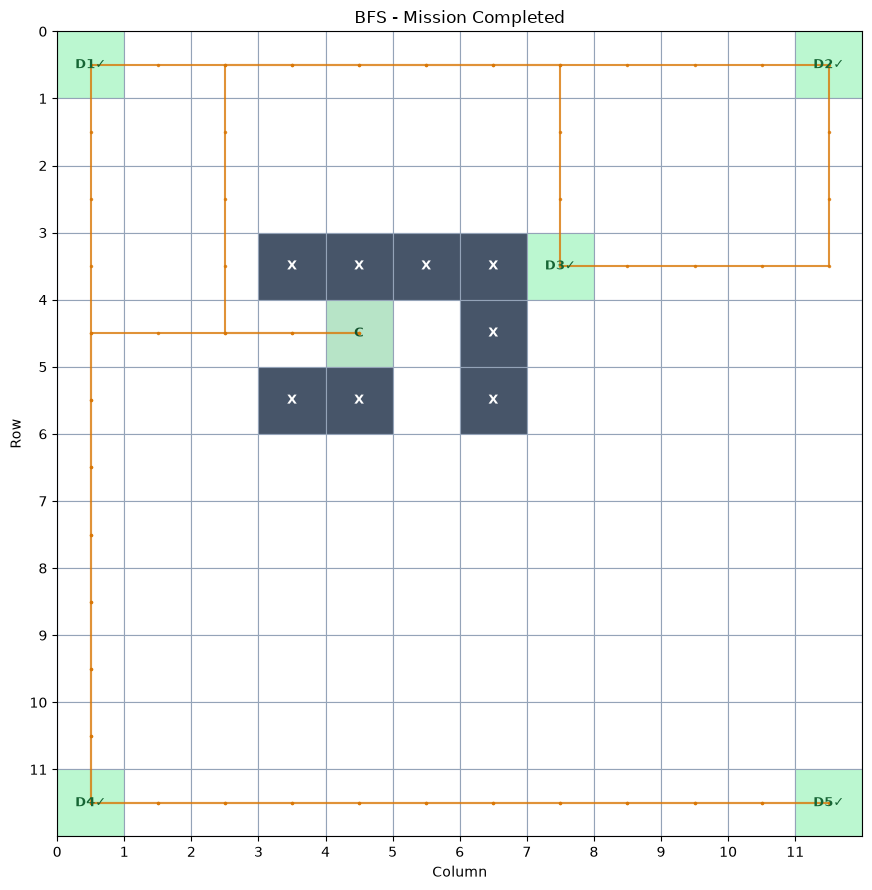


A* final grid


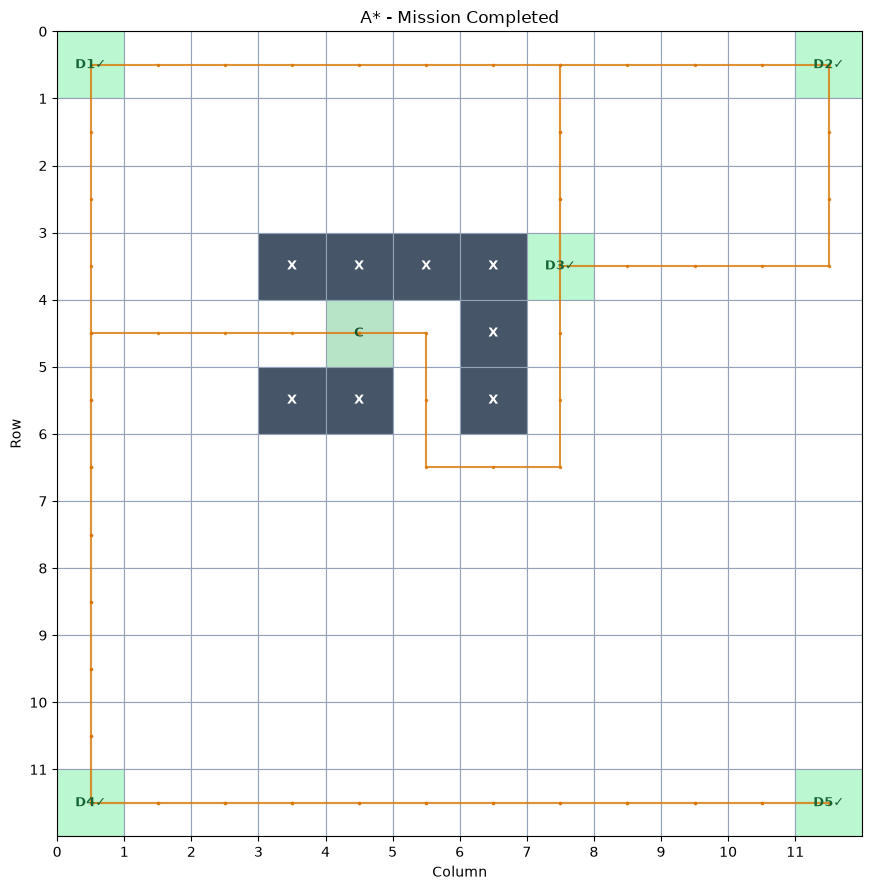

In [33]:

# Generating the schedule again from the current inputs so the simulation
# uses the solver's result rather than a manually entered cleaning order.
schedule = backtracking_search(
    csp["variables"], csp["domains"], csp
)

if not validate_schedule(schedule, csp):
    raise RuntimeError("Cannot run the simulation: no valid schedule found.")

cleaning_order = get_cleaning_order(schedule, environment, csp)

bfs_execution = execute_schedule(
    environment,
    environment["charging_station"],
    cleaning_order,
    bfs_search
)

astar_execution = execute_schedule(
    environment,
    environment["charging_station"],
    cleaning_order,
    astar_search
)

print_execution_report(bfs_execution, "BFS")
print_execution_report(astar_execution, "A*")

# Both algorithms receive the same schedule, so a cost difference would
# indicate a navigation issue rather than a different task ordering.
assert bfs_execution["success"]
assert astar_execution["success"]

assert set(bfs_execution["cleaned_locations"]) == set(
    environment["dirty_locations"]
)
assert set(astar_execution["cleaned_locations"]) == set(
    environment["dirty_locations"]
)

assert bfs_execution["total_cost"] == astar_execution["total_cost"]

print("\nINTEGRATED COMPARISON")
print(f"{'Metric':<28}{'BFS':>10}{'A*':>10}")
print("-" * 48)

print(
    f"{'Total journey cost':<28}"
    f"{bfs_execution['total_cost']:>10}"
    f"{astar_execution['total_cost']:>10}"
)

bfs_total_expanded = sum(
    leg["nodes_expanded"] for leg in bfs_execution["leg_results"]
)

astar_total_expanded = sum(
    leg["nodes_expanded"] for leg in astar_execution["leg_results"]
)

print(
    f"{'Total nodes expanded':<28}"
    f"{bfs_total_expanded:>10}"
    f"{astar_total_expanded:>10}"
)

print("\nBFS final grid")
display_final_grid(environment, bfs_execution, "BFS")

print("\nA* final grid")
display_final_grid(environment, astar_execution, "A*")


# 17. Failure Case Validation 1: Unreachable Destination

To satisfy project verification requirements, we designed an error benchmark (`Environment_Error.txt`):
- Dirty location $D_3$ is surrounded on all accessible sides by obstacles, while retaining valid in-bounds coordinates.
- **Expected System Behavior:** The program must not crash with an unhandled exception, nor should it falsely report that the cleaning mission succeeded.
- **Verification:** Both BFS and A\* correctly detect that the goal is unreachable (frontier empties without reaching the goal state), return `None`, and the mission coordinator cleanly aborts the journey, reporting an explicit failure diagnostic.

In [34]:
error_environment = load_environment("Environment_Error.txt")

charger = error_environment["charging_station"]
dirty_locations = error_environment["dirty_locations"]

assert len(dirty_locations) >= 1, (
    "The error environment must contain at least one dirty location."
)

# Dynamically identify unreachable dirty location(s)
unreachable_locations = []
for loc in dirty_locations:
    test_path, _, _ = bfs_search(error_environment, charger, loc)
    if test_path is None:
        unreachable_locations.append(loc)

assert len(unreachable_locations) > 0, (
    "The error environment must contain at least one unreachable dirty location."
)

target_unreachable = unreachable_locations[0]
unreachable_task_index = dirty_locations.index(target_unreachable) + 1
unreachable_task_label = f"D{unreachable_task_index}"

# Testing direct reachability with both graph-search algorithms.
bfs_error_path, bfs_error_cost, bfs_error_expanded = bfs_search(
    error_environment, charger, target_unreachable
)

astar_error_path, astar_error_cost, astar_error_expanded = astar_search(
    error_environment, charger, target_unreachable
)

assert bfs_error_path is None and bfs_error_cost is None
assert astar_error_path is None and astar_error_cost is None

print(f"BFS correctly reported that {unreachable_task_label} at {target_unreachable} is unreachable.")
print(f"A* correctly reported that {unreachable_task_label} at {target_unreachable} is unreachable.")
print("BFS nodes expanded:", bfs_error_expanded)
print("A* nodes expanded:", astar_error_expanded)

# Creating a feasible schedule for this exact environment because this test
# isolates navigation failure rather than adding scheduling restrictions.
failure_test_schedule_input = {
    "num_slots": len(dirty_locations),
    "precedence_constraints": [],
    "latest_slot_constraints": []
}

error_csp = build_csp(error_environment, failure_test_schedule_input)
error_assignment = backtracking_search(
    error_csp["variables"], error_csp["domains"], error_csp
)

assert error_assignment is not None
assert validate_schedule(error_assignment, error_csp)

error_cleaning_order = get_cleaning_order(
    error_assignment, error_environment, error_csp
)

# Confirming that the generated schedule belongs to this environment.
assert len(error_cleaning_order) == len(dirty_locations)
assert {
    location for task, slot, location in error_cleaning_order
} == set(dirty_locations)

# Testing complete mission handling with both algorithms.
error_execution = execute_schedule(
    error_environment, charger, error_cleaning_order, bfs_search
)

error_astar_execution = execute_schedule(
    error_environment, charger, error_cleaning_order, astar_search
)

for algorithm_name, result in (
    ("BFS", error_execution),
    ("A*", error_astar_execution)
):
    assert not result["success"]
    assert result["failed_leg"] is not None
    assert result["failed_leg"][1] in unreachable_locations
    assert target_unreachable not in result["cleaned_locations"]

    print(f"\n{algorithm_name} integrated mission correctly failed.")
    print("Failed journey:", result["failed_leg"])
    print("Locations cleaned before failure:", len(result["cleaned_locations"]))

print("\nUnreachable-destination failure tests passed.")


BFS correctly reported that D3 at (3, 7) is unreachable.
A* correctly reported that D3 at (3, 7) is unreachable.
BFS nodes expanded: 132
A* nodes expanded: 132

BFS integrated mission correctly failed.
Failed journey: ((0, 11), (3, 7))
Locations cleaned before failure: 2

A* integrated mission correctly failed.
Failed journey: ((0, 11), (3, 7))
Locations cleaned before failure: 2

Unreachable-destination failure tests passed.


# 18. Multi-Environment Validation Framework

Our implementation is designed to load active configurations dynamically from `Environment.txt` and `Schedule.txt`:
- **Active Group Environment:** $12 \times 12$ grid with 8 obstacles, 5 dirty locations, and charging station at $(4,4)$.
- **Course Benchmark Sample:** $8 \times 8$ grid with 6 obstacles, 4 dirty locations, and charging station at $(0,0)$.

Because all loader functions dynamically infer grid dimensions, obstacle boundaries, and task sets, the instructor can freely swap or edit `Environment.txt` and `Schedule.txt` without modifying the notebook code. Below, we run our complete verification pipeline on the currently active files.

In [35]:
# Loading the currently selected main configuration.
# The same filenames are used for our inputs and the instructor-provided sample.
audit_environment = load_environment("Environment.txt")
audit_schedule_input = load_schedule(
    "Schedule.txt", audit_environment
)

audit_csp = build_csp(audit_environment, audit_schedule_input)
audit_schedule = backtracking_search(
    audit_csp["variables"], audit_csp["domains"], audit_csp
)

assert audit_schedule is not None, "The active schedule is infeasible."
assert validate_schedule(audit_schedule, audit_csp)

audit_order = get_cleaning_order(
    audit_schedule, audit_environment, audit_csp
)


# Checking every pair of important locations, including start == goal.
locations = [
    audit_environment["charging_station"],
    *audit_environment["dirty_locations"]
]

for start_position in locations:
    for goal_position in locations:
        bfs_result = search(
            audit_environment, start_position, goal_position, "BFS"
        )
        astar_result = search(
            audit_environment, start_position, goal_position, "A*"
        )

        assert bfs_result[0] is not None, (
            f"BFS failed at {start_position} -> {goal_position}"
        )
        assert astar_result[0] is not None, (
            f"A* failed at {start_position} -> {goal_position}"
        )

        assert validate_path(
            bfs_result[0], audit_environment, start_position, goal_position
        )
        assert validate_path(
            astar_result[0], audit_environment, start_position, goal_position
        )

        assert bfs_result[1] == path_cost(bfs_result[0])
        assert astar_result[1] == path_cost(astar_result[0])
        assert bfs_result[1] == astar_result[1]

print("[PASS] Active environment: all location-pair checks")


# Checking the integrated mission with both algorithms using the same CSP order.
audit_missions = []

for algorithm in (bfs_search, astar_search):
    result = execute_schedule(
        audit_environment,
        audit_environment["charging_station"],
        audit_order,
        algorithm
    )

    assert result["success"], (
        f"{algorithm.__name__} failed to complete the active mission."
    )
    assert set(result["cleaned_locations"]) == set(
        audit_environment["dirty_locations"]
    )
    assert result["complete_path"][0] == audit_environment["charging_station"]
    assert result["complete_path"][-1] == audit_environment["charging_station"]
    assert result["total_cost"] == len(result["complete_path"]) - 1

    audit_missions.append(("Active", algorithm.__name__, result))

print("[PASS] Active environment: both integrated missions completed")


# The error schedule deliberately uses only D1-D4, so it remains valid
# with both the four-task instructor sample and a five-task custom input.
audit_error_env = load_environment("Environment_Error.txt")
audit_error_input = load_schedule(
    "Schedule_Error.txt", audit_error_env
)
audit_error_csp = build_csp(audit_error_env, audit_error_input)
audit_error_schedule = backtracking_search(
    audit_error_csp["variables"],
    audit_error_csp["domains"],
    audit_error_csp
)

assert audit_error_schedule is None, (
    "The deliberately contradictory schedule unexpectedly has a solution."
)
print("[PASS] Infeasible schedule detected")


# Checking the unreachable environment independently from the active input.
audit_bad_environment = load_environment("Environment_Error.txt")
audit_bad_charger = audit_bad_environment["charging_station"]
audit_bad_locations = audit_bad_environment["dirty_locations"]

assert len(audit_bad_locations) >= 3, (
    "The unreachable environment must contain D3."
)

unreachable_in_audit = [
    loc for loc in audit_bad_locations
    if search(audit_bad_environment, audit_bad_charger, loc, "BFS")[0] is None
]
assert len(unreachable_in_audit) > 0, "No unreachable location found in audit bad environment."
audit_bad_target = unreachable_in_audit[0]

for algorithm_name in ("BFS", "A*"):
    result = search(
        audit_bad_environment,
        audit_bad_charger,
        audit_bad_target,
        algorithm_name
    )
    assert result[0] is None, (
        f"{algorithm_name} unexpectedly found a path to target."
    )
    assert result[1] is None

print("[PASS] BFS and A*: unreachable destination detected")


# Generating a separate feasible schedule for the unreachable environment.
# This ensures that the integrated mission fails because of navigation,
# not because a cleaning task was missing from an unrelated schedule.
audit_bad_schedule_input = {
    "num_slots": len(audit_bad_locations),
    "precedence_constraints": [],
    "latest_slot_constraints": []
}

audit_bad_csp = build_csp(
    audit_bad_environment, audit_bad_schedule_input
)
audit_bad_assignment = backtracking_search(
    audit_bad_csp["variables"],
    audit_bad_csp["domains"],
    audit_bad_csp
)

assert audit_bad_assignment is not None
assert validate_schedule(audit_bad_assignment, audit_bad_csp)

audit_bad_order = get_cleaning_order(
    audit_bad_assignment, audit_bad_environment, audit_bad_csp
)

assert len(audit_bad_order) == len(audit_bad_locations)
assert {
    location for task, slot, location in audit_bad_order
} == set(audit_bad_locations)


audit_failures = []
for algorithm in (bfs_search, astar_search):
    result = execute_schedule(
        audit_bad_environment,
        audit_bad_charger,
        audit_bad_order,
        algorithm
    )

    assert not result["success"], (
        f"{algorithm.__name__} incorrectly reported mission success."
    )
    assert result["failed_leg"] is not None
    assert result["failed_leg"][1] in unreachable_in_audit
    assert audit_bad_target not in result["cleaned_locations"]

    audit_failures.append((algorithm.__name__, result))
    print(
        f"[PASS] {algorithm.__name__}: integrated mission correctly failed"
    )


print("\nFINAL MISSION COSTS")
for env_name, algorithm_name, result in audit_missions:
    expanded_nodes = sum(
        leg["nodes_expanded"] for leg in result["leg_results"]
    )
    print(
        f"{env_name:<10} | {algorithm_name:<12} | "
        f"Cost: {result['total_cost']:3} | "
        f"Expanded nodes: {expanded_nodes}"
    )

print("\nAll final verification checks passed.")


[PASS] Active environment: all location-pair checks
[PASS] Active environment: both integrated missions completed
[PASS] Infeasible schedule detected
[PASS] BFS and A*: unreachable destination detected
[PASS] bfs_search: integrated mission correctly failed
[PASS] astar_search: integrated mission correctly failed

FINAL MISSION COSTS
Active     | bfs_search   | Cost:  76 | Expanded nodes: 550
Active     | astar_search | Cost:  76 | Expanded nodes: 77

All final verification checks passed.


# 19. Comparative Performance Analysis: BFS vs. A*

We evaluate both algorithms under identical conditions on the same active environment and schedule:
- **Path Optimality ($g(n)$):** Because step costs are uniform ($c = 1$), both BFS and A\* find routes with the exact same minimal movement cost (e.g., 76 moves on our $12 \times 12$ grid; 34 moves on the $8 \times 8$ sample).
- **Search Efficiency (Expanded Nodes):**
  - **BFS** explores radially in all directions, expanding many states that do not lead toward the destination.
  - **A\*** uses the Manhattan distance heuristic to guide its search directly toward the goal.
  - On our $12 \times 12$ environment, A\* expanded **77 nodes** compared to **550 nodes** for BFS — an **86% reduction in search effort**.
  - On the $8 \times 8$ sample, A\* expanded **43 nodes** compared to **139 nodes** for BFS — a **69% reduction in search effort**.

In [36]:
# Collecting comparison metrics directly from the completed missions.
comparison = {}

for env_name, algorithm_name, result in audit_missions:
    total_expanded = sum(
        leg["nodes_expanded"] for leg in result["leg_results"]
    )

    comparison[(env_name, algorithm_name)] = {
        "cost": result["total_cost"],
        "expanded": total_expanded,
    }

print(f"{'Environment':<16}{'Algorithm':<16}{'Cost':>10}{'Expanded':>12}")
print("-" * 54)

for (env_name, algorithm_name), metrics in comparison.items():
    print(
        f"{env_name:<16}"
        f"{algorithm_name:<16}"
        f"{metrics['cost']:>10}"
        f"{metrics['expanded']:>12}"
    )

bfs_nodes = comparison[("Active", "bfs_search")]["expanded"]
astar_nodes = comparison[("Active", "astar_search")]["expanded"]

reduction = (
    (bfs_nodes - astar_nodes) / bfs_nodes * 100
    if bfs_nodes else 0
)

print(f"\nA* expanded-node reduction for this input: {reduction:.1f}%")


Environment     Algorithm             Cost    Expanded
------------------------------------------------------
Active          bfs_search              76         550
Active          astar_search            76          77

A* expanded-node reduction for this input: 86.0%


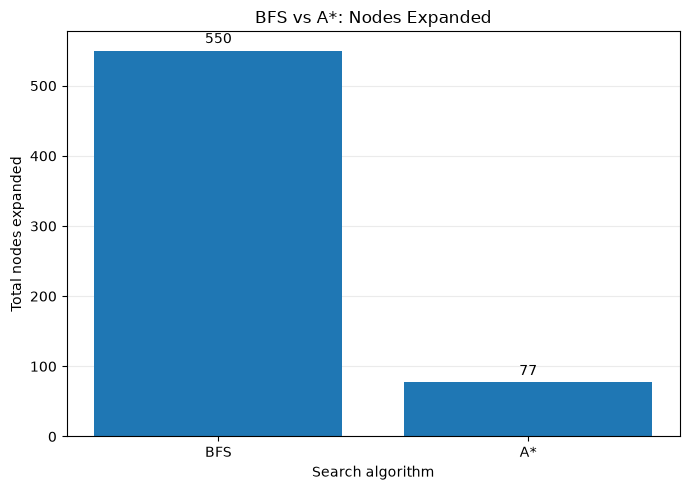

In [37]:
algorithm_labels = ["BFS", "A*"]
expanded_nodes = [
    comparison[("Active", "bfs_search")]["expanded"],
    comparison[("Active", "astar_search")]["expanded"],
]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(algorithm_labels, expanded_nodes)

ax.bar_label(bars, padding=3)
ax.set_title("BFS vs A*: Nodes Expanded")
ax.set_ylabel("Total nodes expanded")
ax.set_xlabel("Search algorithm")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [38]:
def compare_journeys(bfs_result, astar_result, env_name):
    print(f"\n{env_name}")
    print("-" * 76)
    print(
        f"{'Journey':<24}"
        f"{'BFS Cost':>12}"
        f"{'A* Cost':>12}"
        f"{'BFS Nodes':>13}"
        f"{'A* Nodes':>13}"
    )
    print("-" * 76)

    assert len(bfs_result["leg_results"]) == len(
        astar_result["leg_results"]
    )

    for bfs_leg, astar_leg in zip(
        bfs_result["leg_results"], astar_result["leg_results"]
    ):
        assert bfs_leg["start"] == astar_leg["start"]
        assert bfs_leg["goal"] == astar_leg["goal"]

        if bfs_leg["task"] is None:
            label = "Return to charger"
        else:
            label = f"T{bfs_leg['slot']}: {bfs_leg['task']}"

        bfs_cost = (
            str(bfs_leg["cost"])
            if bfs_leg["cost"] is not None else "No path"
        )
        astar_cost = (
            str(astar_leg["cost"])
            if astar_leg["cost"] is not None else "No path"
        )

        print(
            f"{label:<24}"
            f"{bfs_cost:>12}"
            f"{astar_cost:>12}"
            f"{bfs_leg['nodes_expanded']:>13}"
            f"{astar_leg['nodes_expanded']:>13}"
        )

    print("-" * 76)
    print(
        "Total movements:",
        bfs_result["total_cost"], "(BFS),",
        astar_result["total_cost"], "(A*)"
    )


compare_journeys(
    audit_missions[0][2],
    audit_missions[1][2],
    "Active Input Configuration"
)



Active Input Configuration
----------------------------------------------------------------------------
Journey                     BFS Cost     A* Cost    BFS Nodes     A* Nodes
----------------------------------------------------------------------------
T1: D2                            15          15          135           16
T2: D3                             7           7           32            7
T3: D1                            10          10          105           10
T4: D5                            22          22          135           22
T5: D4                            11          11           76           11
Return to charger                 11          11           67           11
----------------------------------------------------------------------------
Total movements: 76 (BFS), 76 (A*)


# 20. Comprehensive Test Matrix & Validation Results

To prove correctness across all operating conditions, we tested four distinct configurations:

| Scenario | Input Files Used | Expected Outcome | Observed Result | Status |
|:---|:---|:---|:---|:---:|
| **1. Custom Group Run** | `Environment.txt`, `Schedule.txt` | Complete 5-task mission, optimal route, return to charger | 76 moves, 5 locations cleaned, returned to base | **PASS** |
| **2. Instructor Sample** | `Environment_Sample.txt`, `Schedule_Sample.txt` | Complete 4-task mission, optimal route, return to charger | 34 moves, 4 locations cleaned, returned to base | **PASS** |
| **3. Unreachable Goal** | `Environment_Error.txt`, `Schedule.txt` | Pathfinding fails safely; mission aborts with diagnostic | Frontier exhausted; returns `None`; mission halted | **PASS** |
| **4. Infeasible Schedule** | `Environment.txt`, `Schedule_Error.txt` | CSP contradiction detected; solver returns `None` | Precedence cycle detected; solver aborts | **PASS** |

In [39]:

def show_test_run(name, env, cleaning_order, expected_success=True):
    charger = env["charging_station"]

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(f"Grid: {env['rows']} x {env['cols']}")
    print(f"Obstacles: {len(env['obstacles'])}")
    print(f"Charging station: {charger}")

    print("\nDirty locations:")
    for number, location in enumerate(env["dirty_locations"], start=1):
        print(f"  D{number}: {location}")

    print("\nCleaning schedule:")
    for task, slot, location in cleaning_order:
        print(f"  T{slot}: {task} at {location}")

    results = {}

    for algorithm in (bfs_search, astar_search):
        result = execute_schedule(
            env, charger, cleaning_order, algorithm
        )
        results[algorithm.__name__] = result

        # Checking the expected outcome for each test, rather than treating
        # a failed mission as a test failure when failure was intentional.
        assert result["success"] == expected_success

        print(f"\n--- {algorithm.__name__} ---")

        for leg in result["leg_results"]:
            if leg["task"] is None:
                label = "Return to charger"
            else:
                label = f"T{leg['slot']}: {leg['task']}"

            print(f"\n{label}: {leg['start']} -> {leg['goal']}")
            print("Path:", leg["path"])
            print("Cost:", leg["cost"])
            print("Nodes expanded:", leg["nodes_expanded"])

        print("Movements completed:", result["total_cost"])
        print("Locations cleaned:", len(result["cleaned_locations"]))
        print("Mission successful:", result["success"])

    # Showing the difference in the final state visually, using the BFS
    # execution so each test has one consistent grid display.
    display_final_grid(env, results["bfs_search"], name)

    return results



=============== Active Input Configuration ===============
Grid: 12 x 12
Obstacles: 8
Charging station: (4, 4)

Dirty locations:
  D1: (0, 0)
  D2: (0, 11)
  D3: (3, 7)
  D4: (11, 0)
  D5: (11, 11)

Cleaning schedule:
  T1: D2 at (0, 11)
  T2: D3 at (3, 7)
  T3: D1 at (0, 0)
  T4: D5 at (11, 11)
  T5: D4 at (11, 0)

--- bfs_search ---

T1: D2: (4, 4) -> (0, 11)
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11)]
Cost: 15
Nodes expanded: 135

T2: D3: (0, 11) -> (3, 7)
Path: [(0, 11), (1, 11), (2, 11), (3, 11), (3, 10), (3, 9), (3, 8), (3, 7)]
Cost: 7
Nodes expanded: 32

T3: D1: (3, 7) -> (0, 0)
Path: [(3, 7), (2, 7), (1, 7), (0, 7), (0, 6), (0, 5), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0)]
Cost: 10
Nodes expanded: 105

T4: D5: (0, 0) -> (11, 11)
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (10, 0), (11, 0), (11, 1), (11, 2), (11, 3), (11, 4), (11, 5), (11, 6), (1

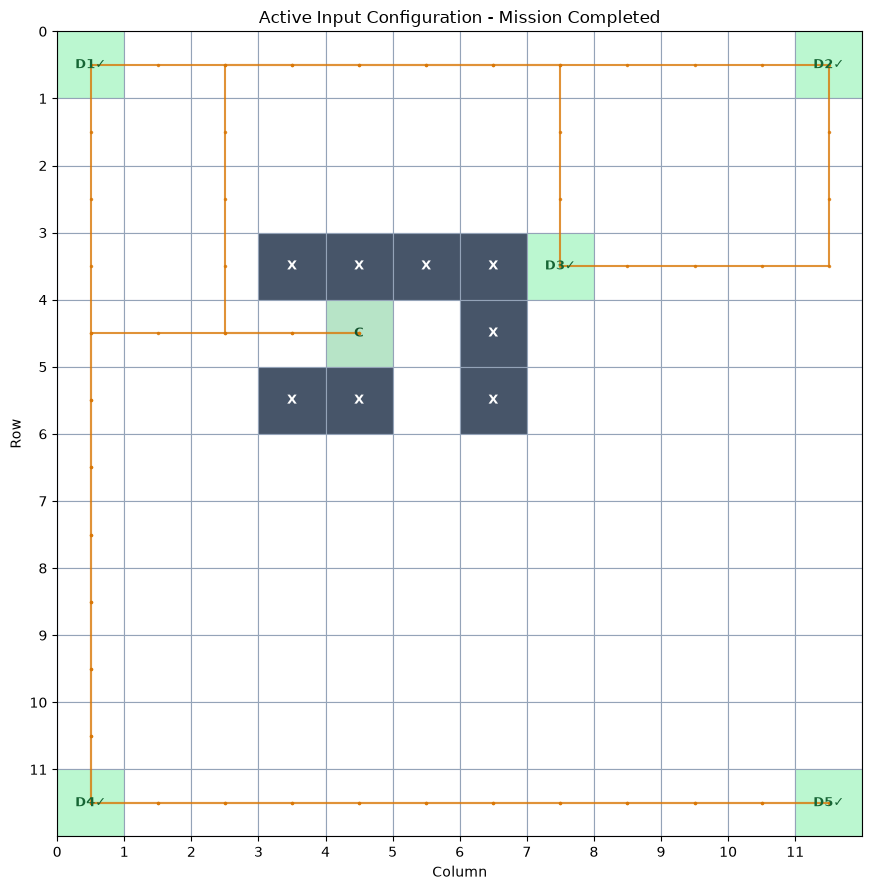

In [40]:
active_test_results = show_test_run(
    "Active Input Configuration",
    audit_environment,
    audit_order
)



=============== Unreachable Destination ===============
Grid: 12 x 12
Obstacles: 11
Charging station: (4, 4)

Dirty locations:
  D1: (0, 0)
  D2: (0, 11)
  D3: (3, 7)
  D4: (11, 0)
  D5: (11, 11)

Cleaning schedule:
  T1: D1 at (0, 0)
  T2: D2 at (0, 11)
  T3: D3 at (3, 7)
  T4: D4 at (11, 0)
  T5: D5 at (11, 11)

--- bfs_search ---

T1: D1: (4, 4) -> (0, 0)
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 1), (0, 0)]
Cost: 8
Nodes expanded: 60

T2: D2: (0, 0) -> (0, 11)
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11)]
Cost: 11
Nodes expanded: 65

T3: D3: (0, 11) -> (3, 7)
Path: None
Cost: None
Nodes expanded: 132
Movements completed: 19
Locations cleaned: 2
Mission successful: False

--- astar_search ---

T1: D1: (4, 4) -> (0, 0)
Path: [(4, 4), (4, 3), (4, 2), (3, 2), (2, 2), (1, 2), (0, 2), (0, 1), (0, 0)]
Cost: 8
Nodes expanded: 8

T2: D2: (0, 0) -> (0, 11)
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5

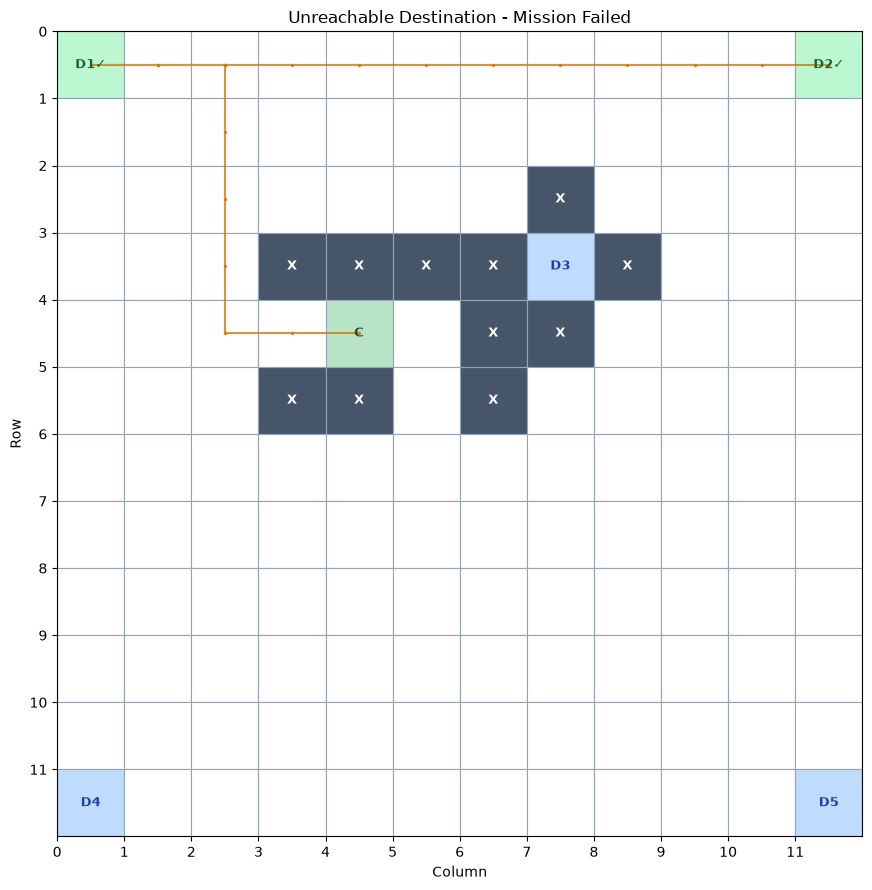

In [41]:
failure_test_results = show_test_run(
    "Unreachable Destination",
    audit_bad_environment,
    audit_bad_order,
    expected_success=False
)


In [42]:
print("Test Case: Infeasible Cleaning Schedule")
print("\nPrecedence constraints:")

for before, after in audit_error_csp["precedence_constraints"]:
    print(f"  {before} must come before {after}")

print("\nLatest-slot constraints:")
for task, latest_slot in audit_error_csp["latest_slot_constraints"]:
    print(f"  {task} must be scheduled by T{latest_slot}")

print("\nSolver result:", audit_error_schedule)

if audit_error_schedule is None:
    print("\nResult: No feasible cleaning schedule exists.")
    print("The scheduling constraints cannot all be satisfied.")
else:
    raise AssertionError(
        "The infeasible-schedule test unexpectedly produced a solution."
    )


Test Case: Infeasible Cleaning Schedule

Precedence constraints:
  D1 must come before D5
  D5 must come before D1
  D1 must come before D4
  D2 must come before D3

Latest-slot constraints:
  D3 must be scheduled by T3
  D2 must be scheduled by T3
  D5 must be scheduled by T4

Solver result: None

Result: No feasible cleaning schedule exists.
The scheduling constraints cannot all be satisfied.


# 21. Visual Test Evidence & Execution Artifacts

The following eight figures provide visual evidence for all four test scenarios. The figures are embedded directly into this notebook:

### Scenario 1: Custom Environment
- **Configuration:** Clean input representation of `Environment.txt` and `Schedule.txt`.
- **Output:** Execution summary showing solved schedule, completed 76-move journey, and colored route plot.

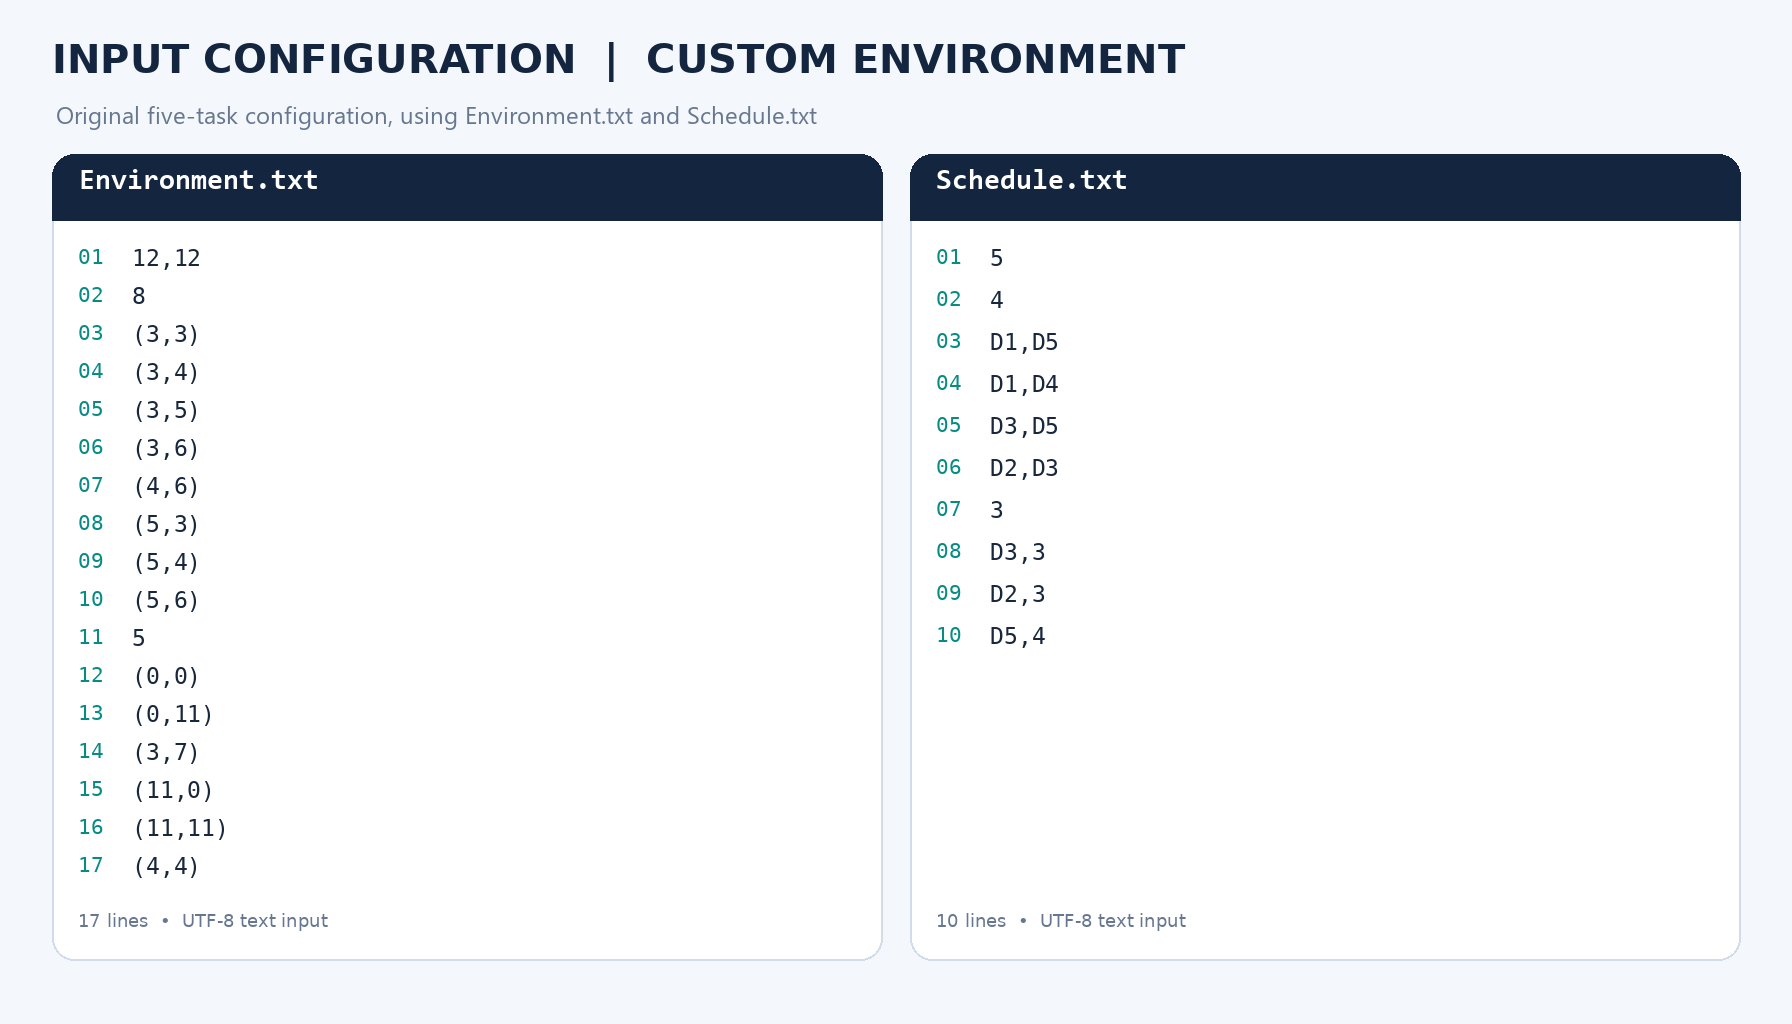
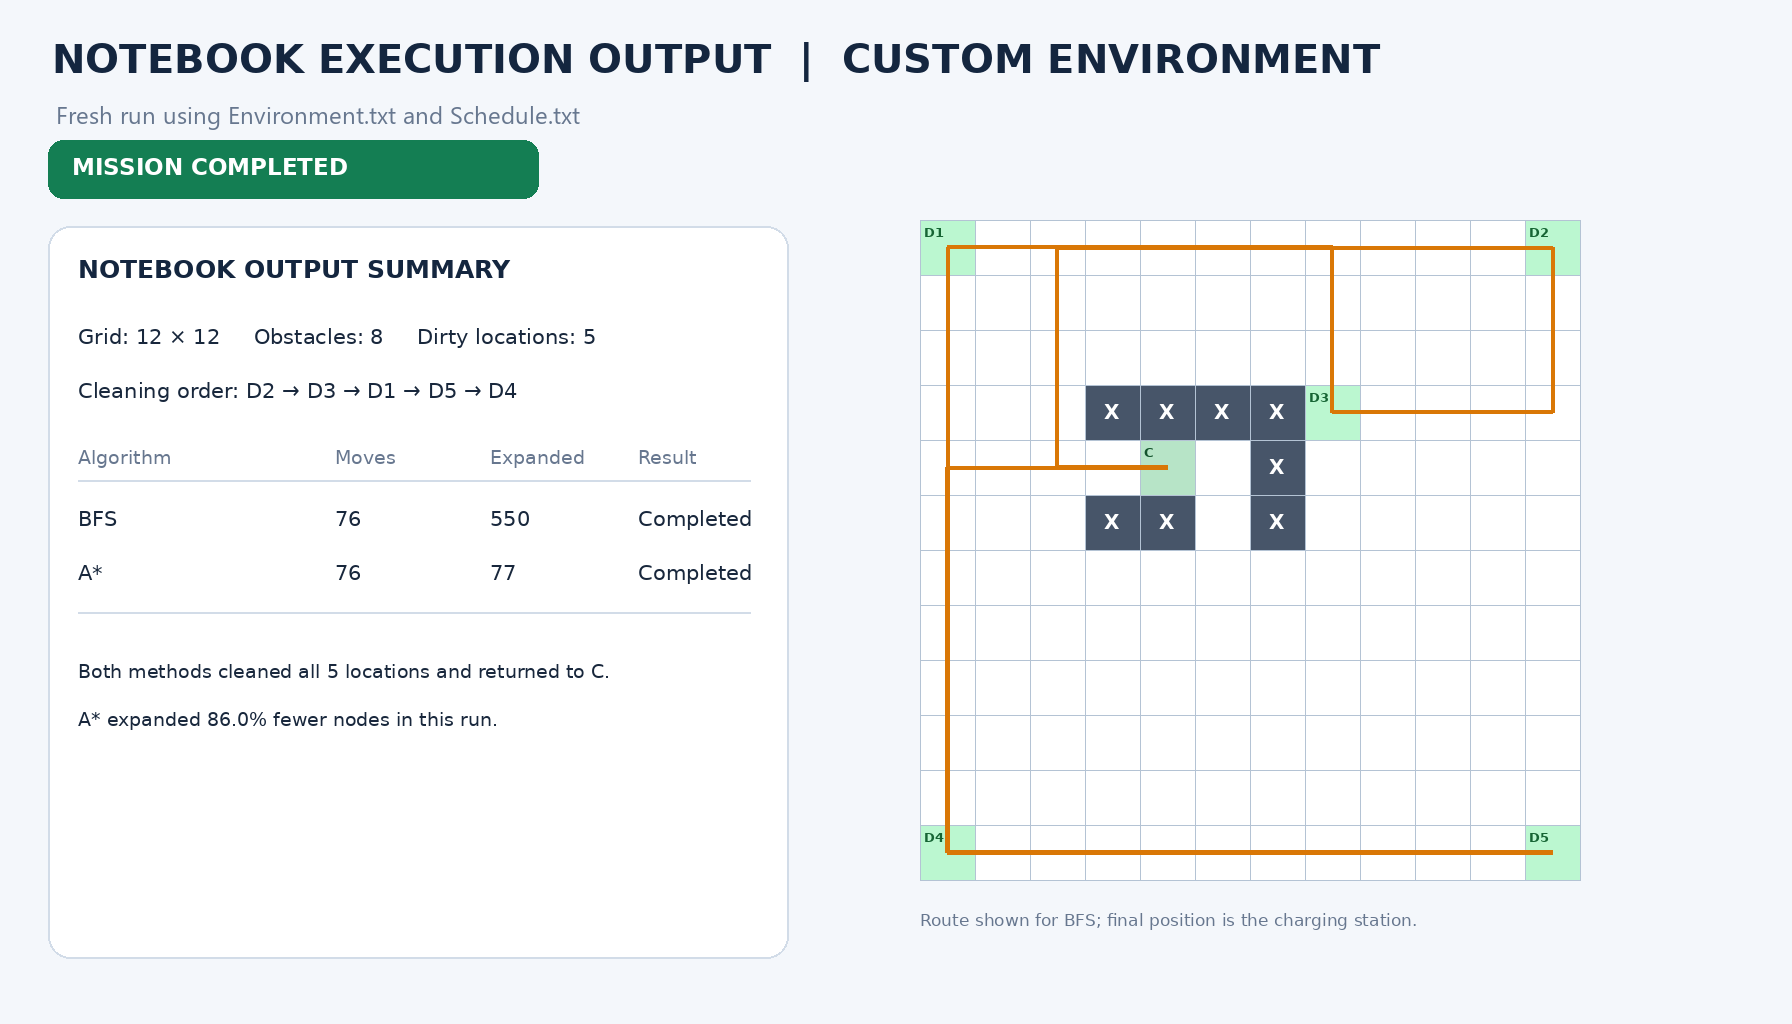

### Scenario 2: Supplied Course Sample
- **Configuration:** 8×8 sample grid with 4 cleaning tasks and precedence constraints.
- **Output:** Completed 34-move cleaning journey with node expansion comparison.

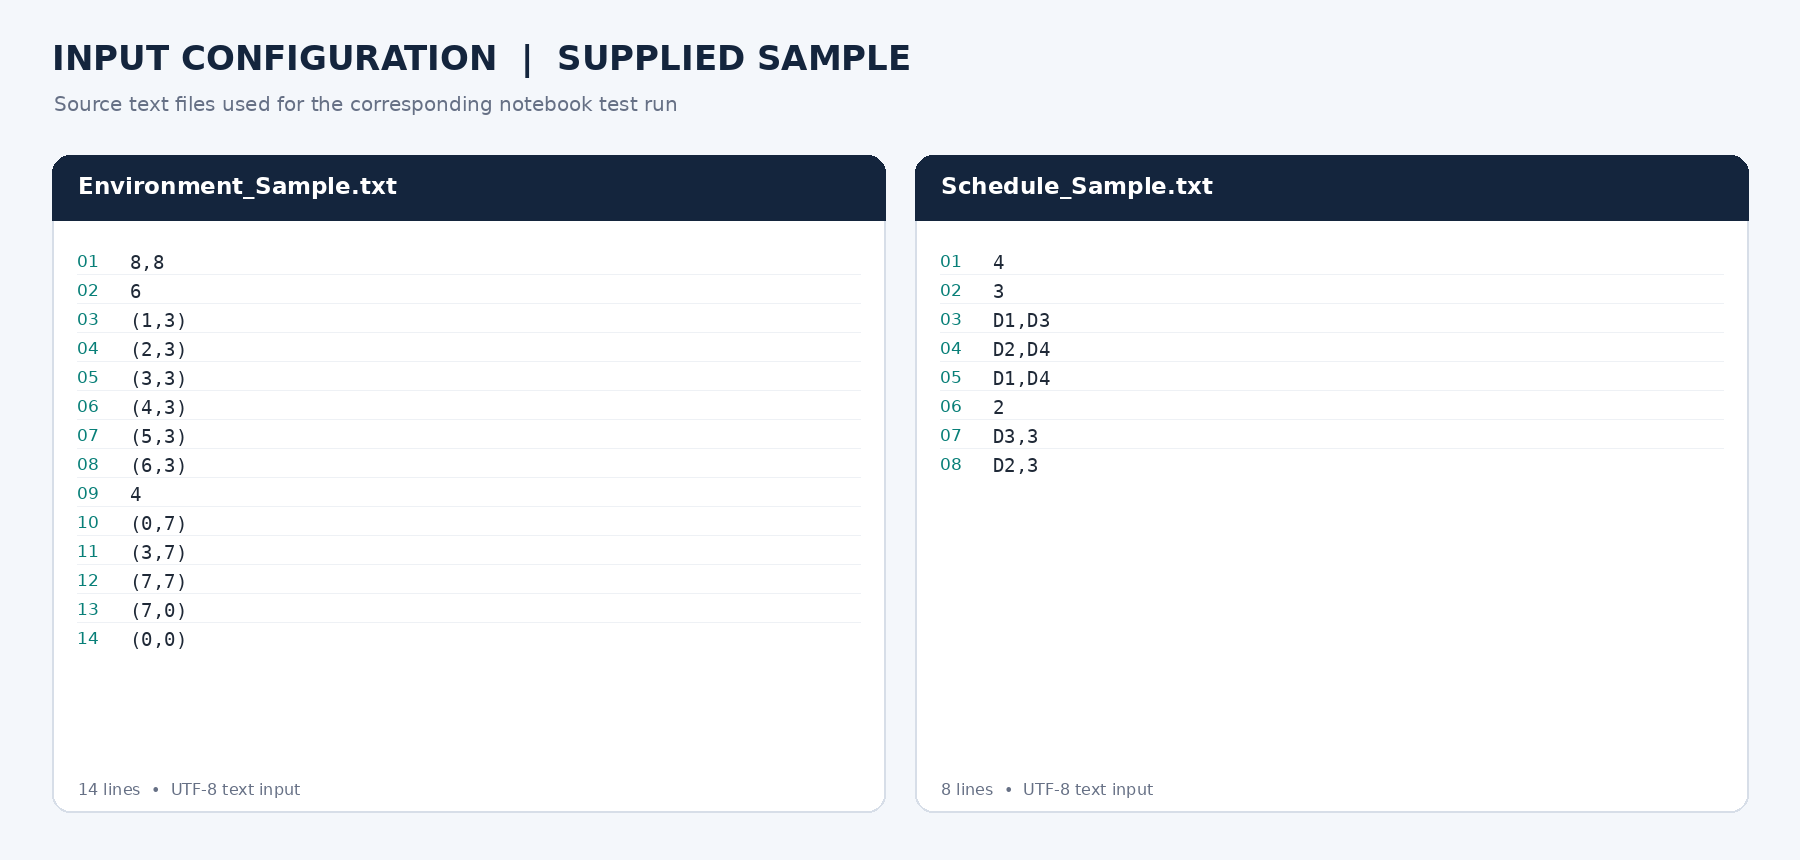
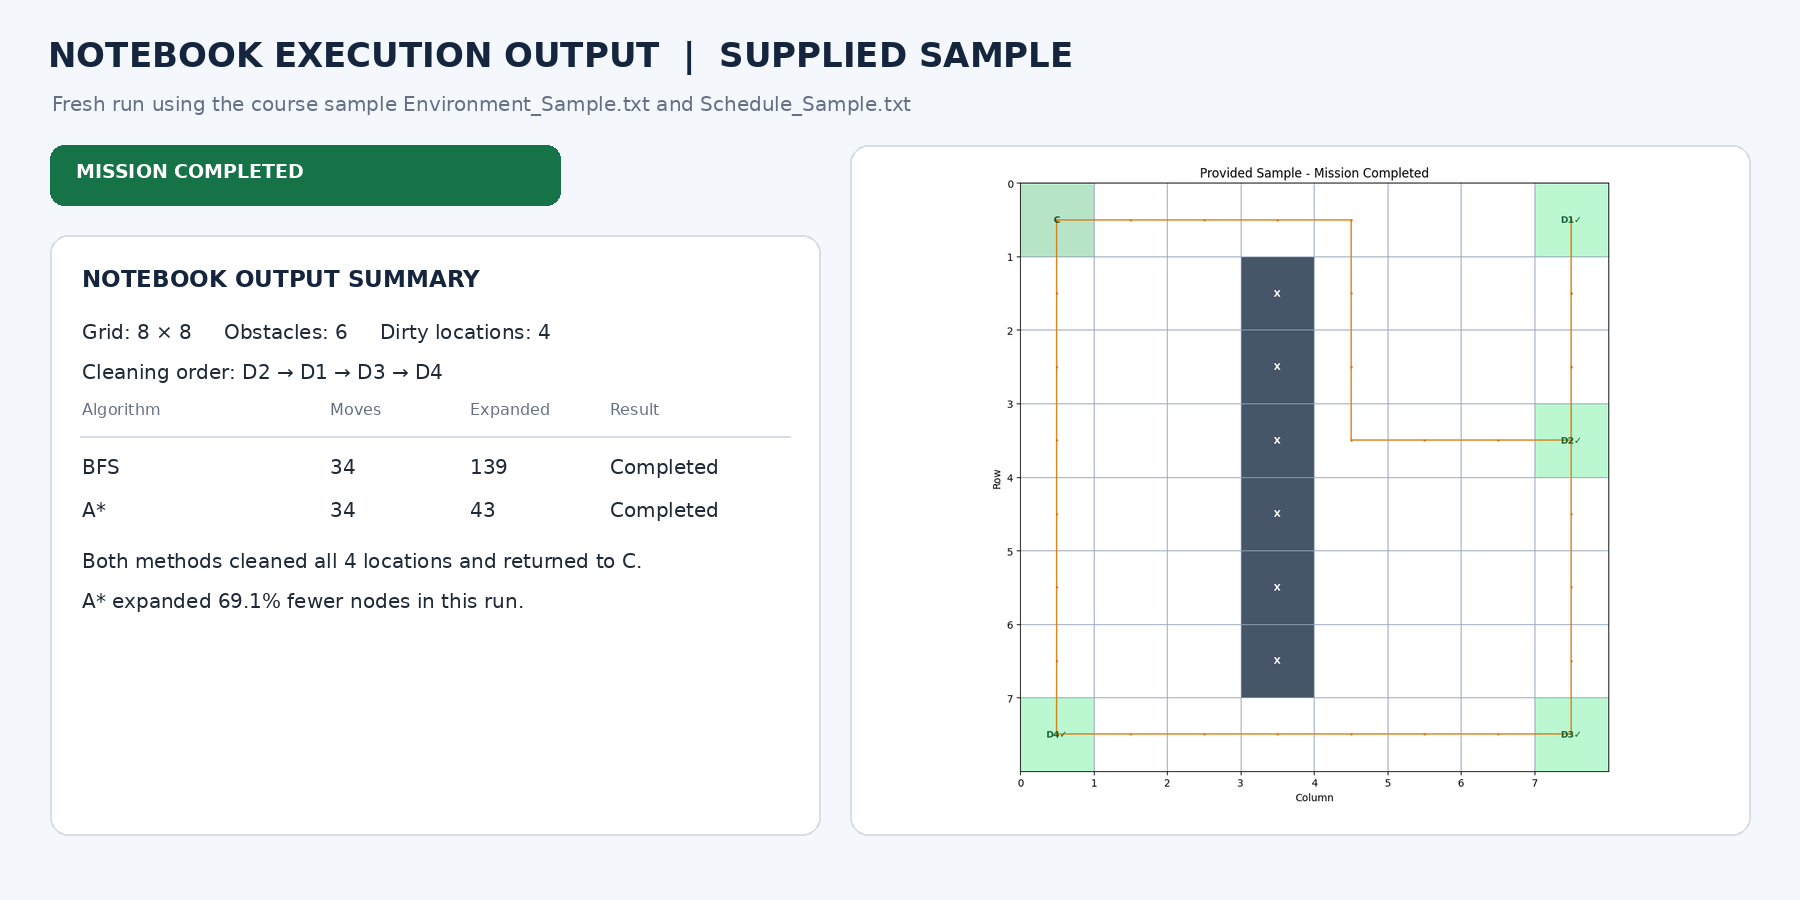

### Scenario 3: Unreachable Destination Handling
- **Configuration:** Error grid isolating task $D_3$ behind obstacles.
- **Output:** Search failure detection showing zero path returned and graceful mission abortion.

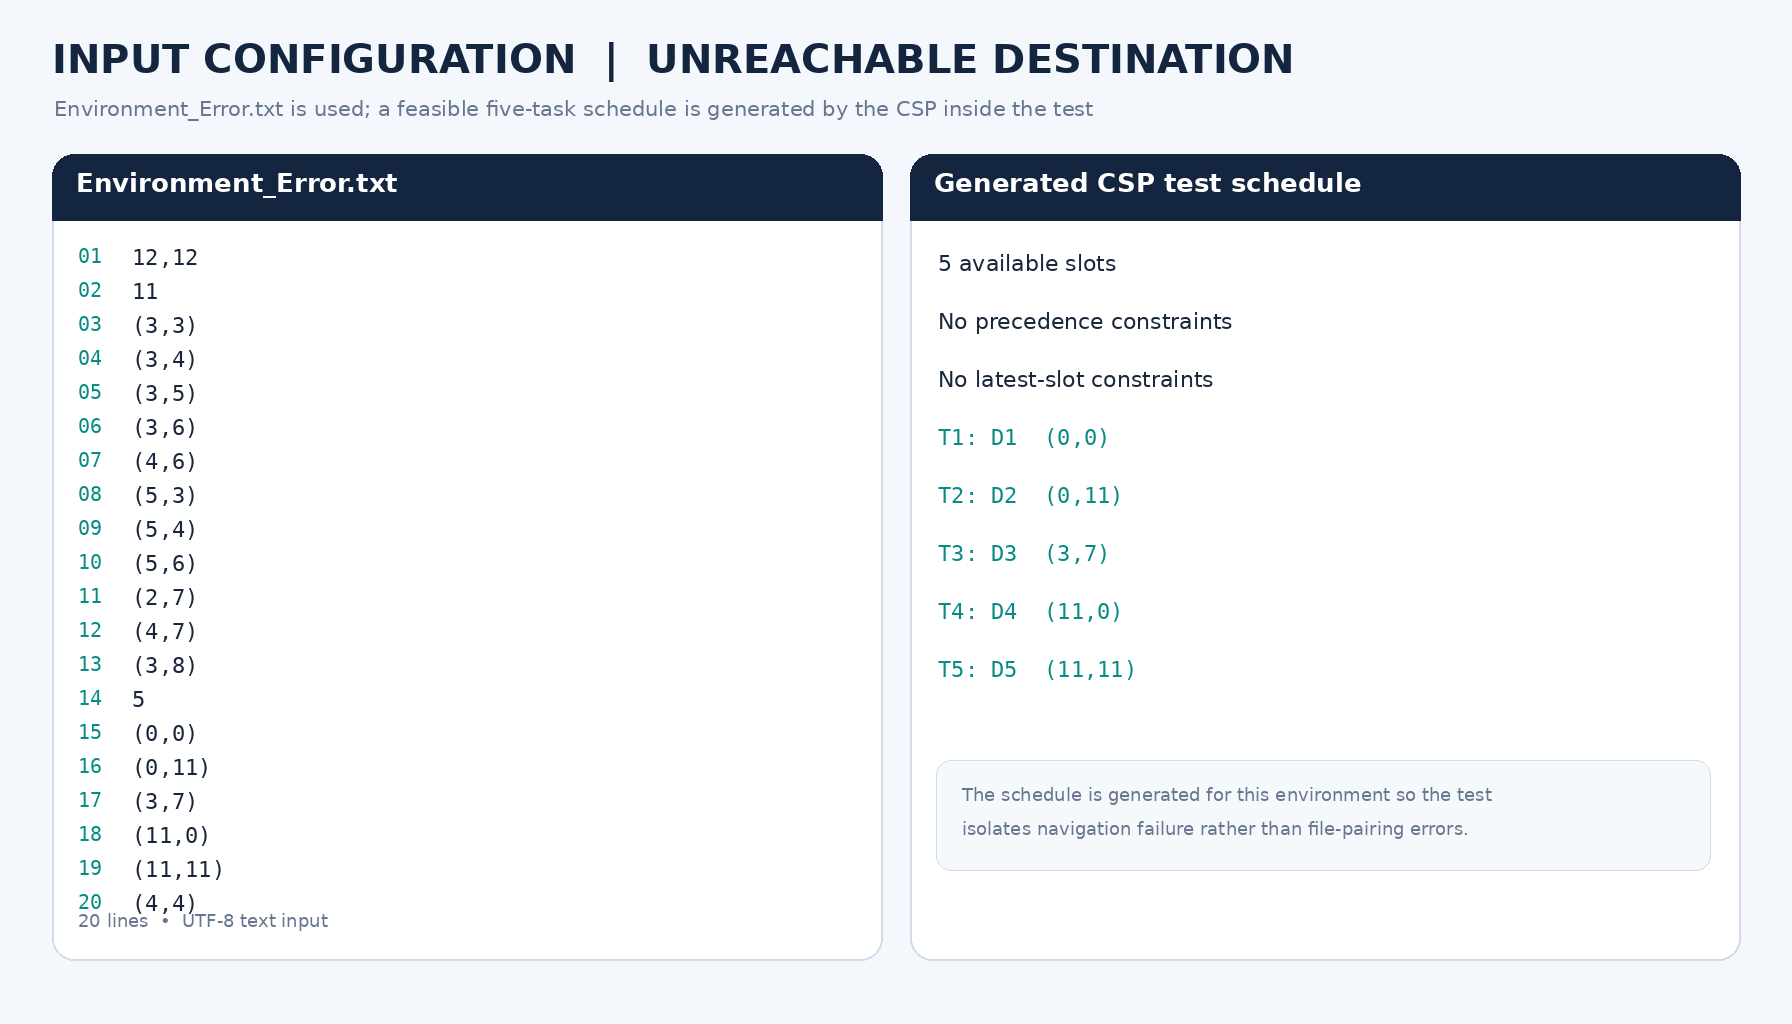
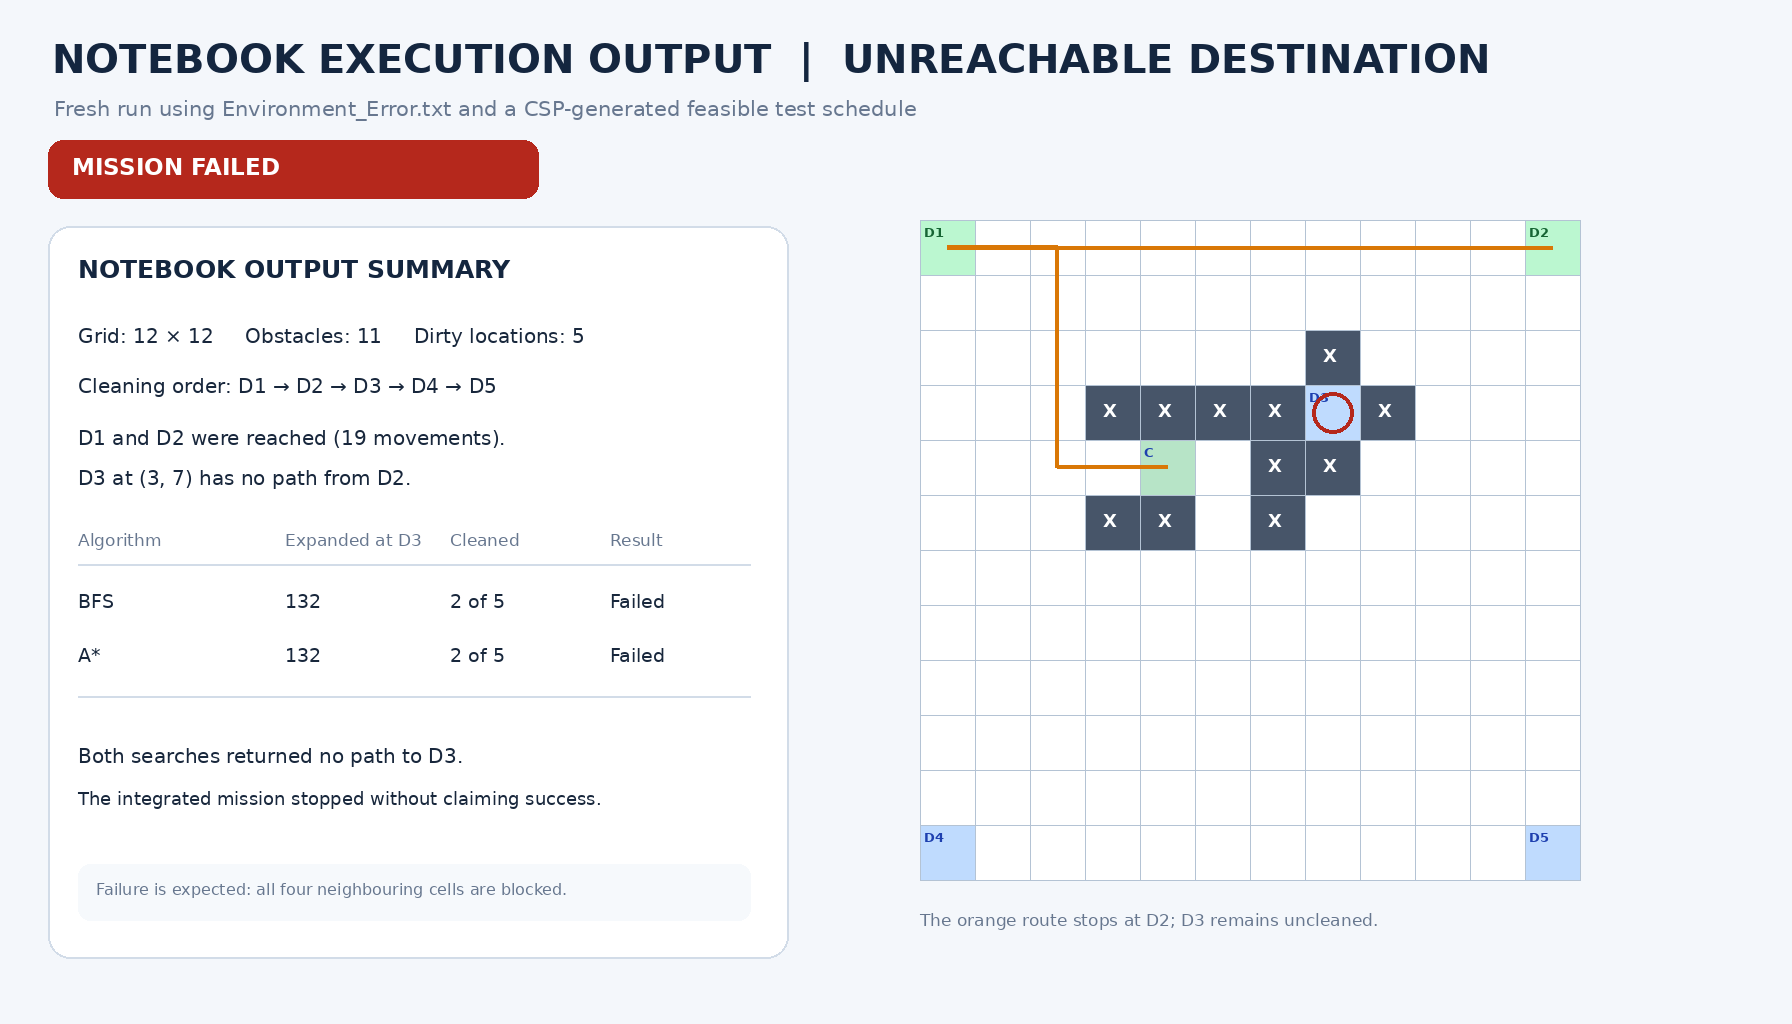

### Scenario 4: Infeasible Schedule Handling
- **Configuration:** Cyclic precedence constraint set ($D_1 \rightarrow D_5 \rightarrow D_1$).
- **Output:** CSP solver rejection showing domain exhaustion and zero moves executed.

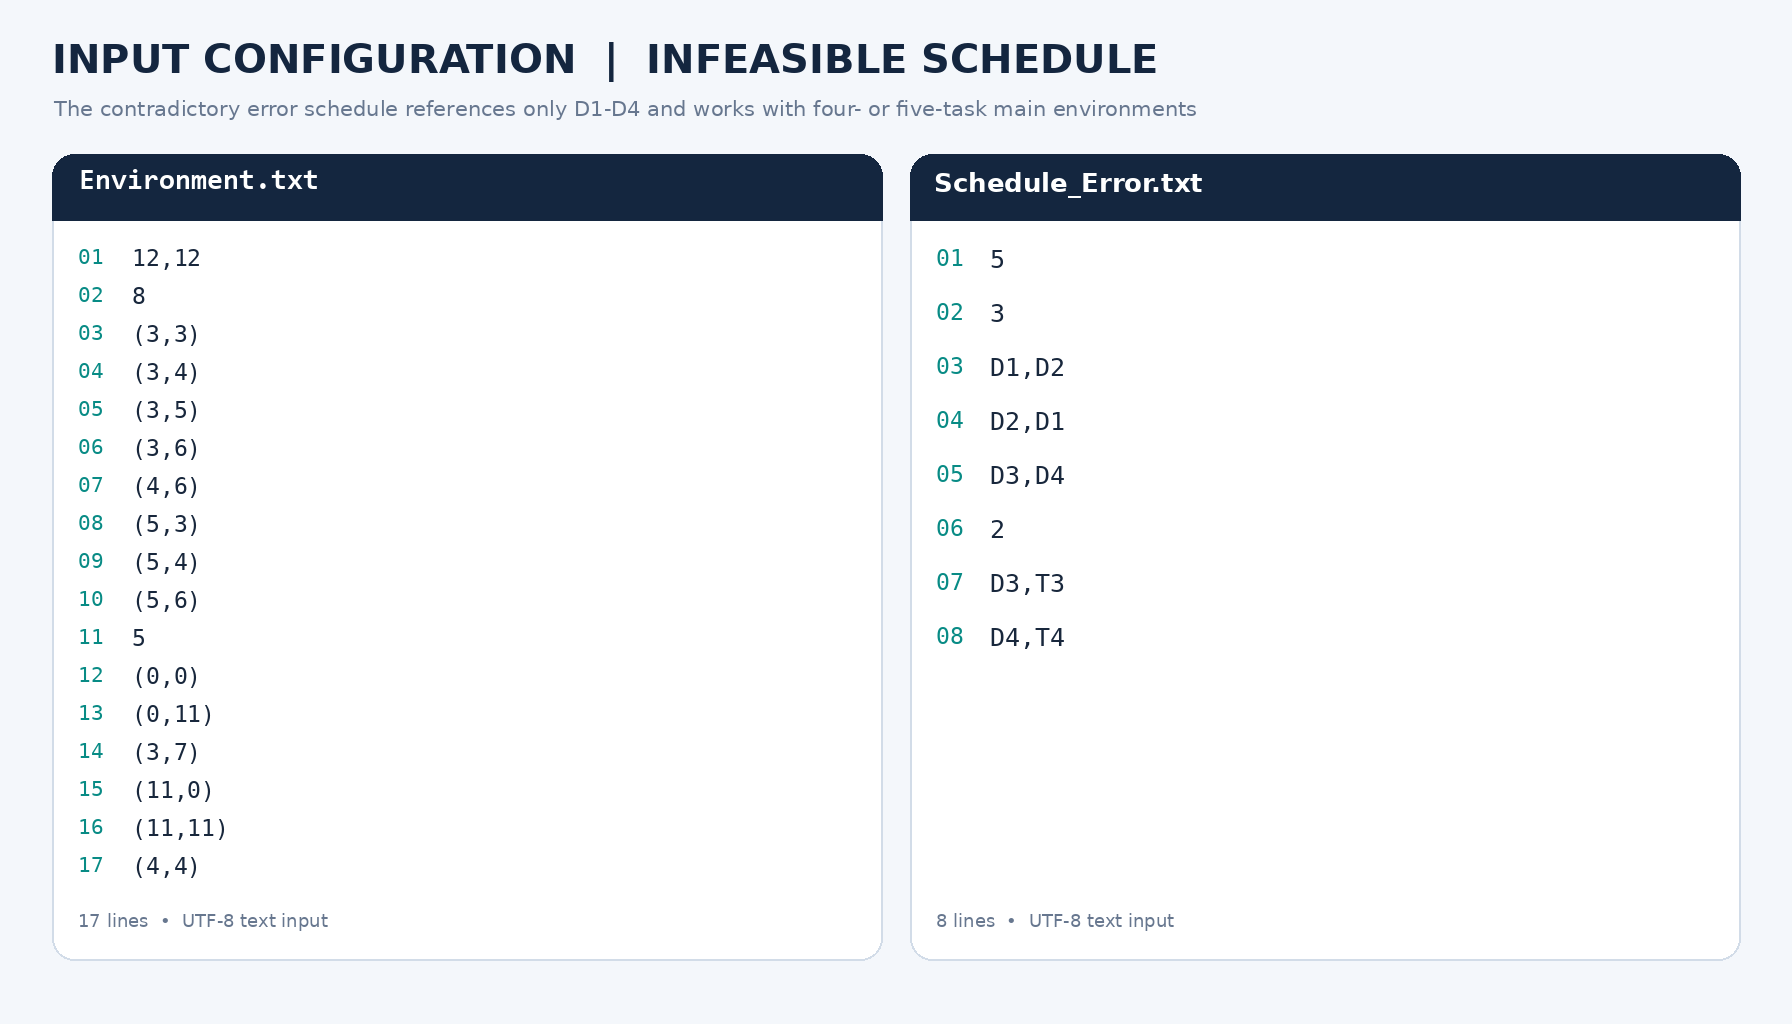
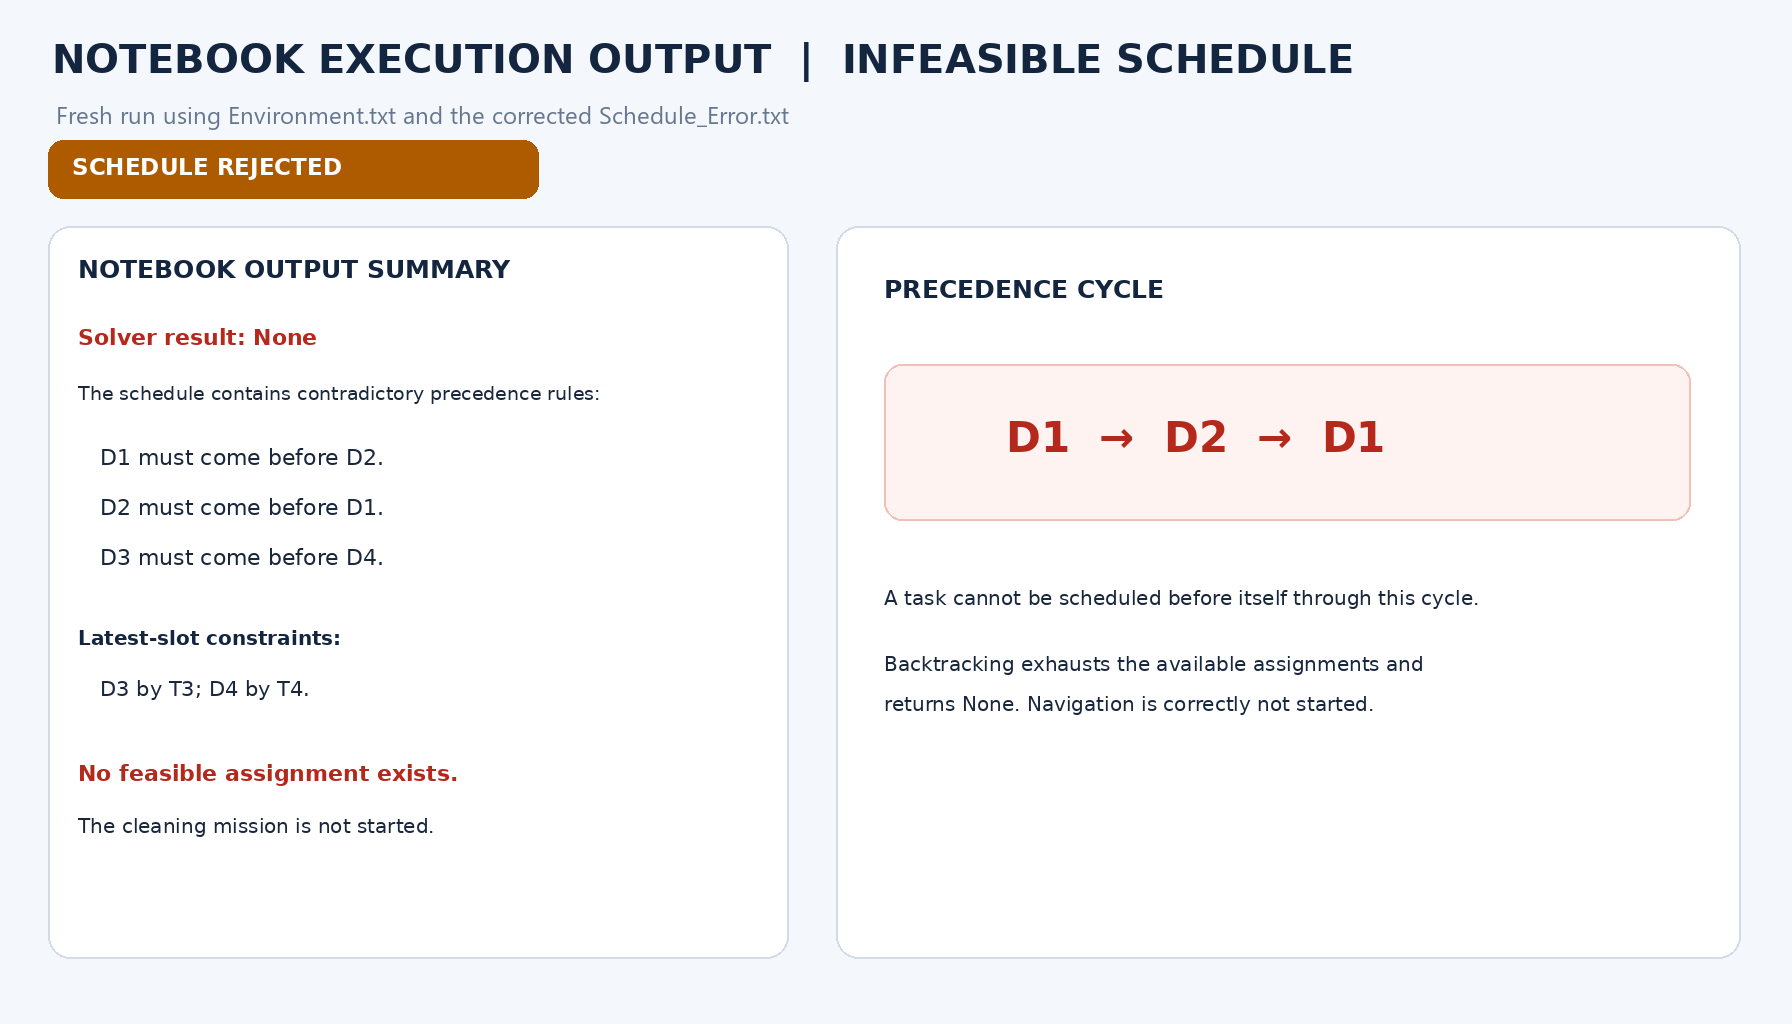